# Milestone 1: EDA and Problem Formulation

FPA-FOD 7th edition (2.66 M US wildfires, 1992-2024) joined with the HIFLD Fire and EMS Stations layer (52 k stations).

Research questions:

1. **Supervised:** does a fire's distance to the nearest fire station change how likely it is to become large, after accounting for where, when and why it started?
2. **Unsupervised:** among areas that have fires but no station nearby, what distinct types exist, and what kind of help would each type need?

Plan:
- **Part A (sections 1-4):** profile the wildfire table on its own: data quality, when, where and how big fires are.
- **Part B (sections 5-10):** explain why a second dataset is needed, profile it, join it to the fires, then do the EDA for each question and check that each one is viable.

**To run:** put `FPA_FOD_20260615.sqlite` in `wildfire_7th_edition_data/Data/` and the station GeoJSON in `fire_station_data/Data/` (see the README in each folder), anywhere at or above this notebook's folder. Everything is seeded with `SEED = 281`; a full run takes about half an hour, mostly the logistic fits in section 8 and the LightGBM baselines. Figures are written to `EDA/figures/`.

In [1]:
import json
import os
import sqlite3
from contextlib import closing
from pathlib import Path

os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count()))  # silences a joblib core-count warning on Windows

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (adjusted_rand_score, average_precision_score, davies_bouldin_score, precision_recall_curve,
                             roc_auc_score, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import BallTree, NearestNeighbors
from sklearn.preprocessing import StandardScaler

%matplotlib inline
sns.set_theme(style='whitegrid', palette='colorblind')
SEED = 281


def find_dir(name, sub='Data'):
    # search this folder and its parents so the notebook works from anywhere in the repo
    for d in [Path.cwd(), *Path.cwd().parents]:
        if (d / name / sub).is_dir():
            return d / name / sub
    raise FileNotFoundError(f'{name}/{sub} not found, see the README in that folder for the download link')


DB_PATH = find_dir('wildfire_7th_edition_data') / 'FPA_FOD_20260615.sqlite'
STATIONS_PATH = find_dir('fire_station_data') / 'fire-and-emergency-medical-service-ems-stations-geojson.geojson'
FIG_DIR = DB_PATH.parents[1].parent / 'EDA' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

EARTH_KM = 6371.0
JD_EPOCH = 2440587.5            # julian day number of 1970-01-01
LARGE_ACRES = 100               # size class D and above
SPLIT_YEAR = 2019               # train 1992-2018, test 2019-2024
COVER_KM = 10                   # "covered" = a station within 10 km
WEST = {'WA', 'OR', 'CA', 'ID', 'NV', 'MT', 'WY', 'UT', 'CO', 'AZ', 'NM'}
NOT_CONUS = {'AK', 'HI', 'PR'}
FED_OWNERS = {'USFS', 'BLM', 'NPS', 'FWS', 'BIA', 'BOR', 'OTHER FEDERAL', 'DOD', 'DOE', 'TVA', 'UNDEFINED FEDERAL'}


def savefig(name):
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches='tight')

# Part A: The wildfire data

## Load the data

I load the full table instead of using the starter's `LIMIT 500000 ... WHERE CONT_DATE IS NOT NULL`, since both filters bias the sample (see section 1).

In [2]:
cols = ['FIRE_YEAR', 'DISCOVERY_DATE', 'DISCOVERY_DOY', 'DISCOVERY_TIME', 'CONT_DATE',
        'FIRE_SIZE', 'FIRE_SIZE_CLASS', 'LATITUDE', 'LONGITUDE', 'STATE', 'OWNER_DESCR',
        'NWCG_REPORTING_AGENCY', 'SOURCE_SYSTEM_TYPE', 'NWCG_CAUSE_CLASSIFICATION', 'NWCG_GENERAL_CAUSE']

# peek at the full table (every column) without loading all 2.6 M rows into memory
with closing(sqlite3.connect(DB_PATH)) as conn:
    n_rows = conn.execute('SELECT COUNT(*) FROM Fires').fetchone()[0]
    preview = pd.read_sql_query('SELECT * FROM Fires LIMIT 5', conn)

print(f'Full table: {n_rows:,} rows x {preview.shape[1]} columns')
pd.set_option('display.max_columns', None)
display(preview)

print(f'\nSelected columns: {len(cols)} of {preview.shape[1]}')
display(preview[cols])

Full table: 2,661,383 rows x 39 columns


,OBJECTID,Shape,FOD_ID,FPA_ID,SOURCE_SYSTEM_TYPE,SOURCE_SYSTEM,NWCG_REPORTING_AGENCY,NWCG_REPORTING_UNIT_ID,NWCG_REPORTING_UNIT_NAME,SOURCE_REPORTING_UNIT,SOURCE_REPORTING_UNIT_NAME,LOCAL_FIRE_REPORT_ID,LOCAL_INCIDENT_ID,FIRE_CODE,FIRE_NAME,ICS_209_PLUS_INCIDENT_JOIN_ID,ICS_209_PLUS_COMPLEX_JOIN_ID,MTBS_ID,MTBS_FIRE_NAME,COMPLEX_NAME,FIRE_YEAR,DISCOVERY_DATE,DISCOVERY_DOY,DISCOVERY_TIME,NWCG_CAUSE_CLASSIFICATION,NWCG_GENERAL_CAUSE,NWCG_CAUSE_AGE_CATEGORY,CONT_DATE,CONT_DOY,CONT_TIME,FIRE_SIZE,FIRE_SIZE_CLASS,LATITUDE,LONGITUDE,OWNER_DESCR,STATE,COUNTY,FIPS_CODE,FIPS_NAME
0,1,b'd\xad\x10\x00\x01\x00\x00\x00\x04\x01\x0c\x0...,1,FS-1418826,FED,FS-FIRESTAT,FS,USCAPNF,Plumas National Forest,0511,Plumas National Forest,1,PNF-47,BJ8K,FOUNTAIN,None,None,None,None,None,2005,2453403.5,33,1300,Human,Power generation/transmission/distribution,None,2453403.5,33,1730,0.10,A,40.036944,-121.005833,USFS,CA,63,06063,Plumas County
1,2,b'd\xad\x10\x00\x01\x00\x00\x00\x04\x01\x0c\x0...,2,FS-1418827,FED,FS-FIRESTAT,FS,USCAENF,Eldorado National Forest,0503,Eldorado National Forest,13,13,AAC0,PIGEON,None,None,None,None,None,2004,2453137.5,133,0845,Natural,Natural,None,2453137.5,133,1530,0.25,A,38.933056,-120.404444,USFS,CA,61,06061,Placer County
2,3,b'd\xad\x10\x00\x01\x00\x00\x00\x04\x01\x0c\x0...,3,FS-1418835,FED,FS-FIRESTAT,FS,USCAENF,Eldorado National Forest,0503,Eldorado National Forest,27,021,A32W,SLACK,None,None,None,None,None,2004,2453156.5,152,1921,Human,Debris and open burning,None,2453156.5,152,2024,0.10,A,38.984167,-120.735556,STATE OR PRIVATE,CA,17,06017,El Dorado County
3,4,b'd\xad\x10\x00\x01\x00\x00\x00\x04\x01\x0c\x0...,4,FS-1418845,FED,FS-FIRESTAT,FS,USCAENF,Eldorado National Forest,0503,Eldorado National Forest,43,6,None,DEER,None,None,None,None,None,2004,2453184.5,180,1600,Natural,Natural,None,2453189.5,185,1400,0.10,A,38.559167,-119.913333,USFS,CA,3,06003,Alpine County
4,5,b'd\xad\x10\x00\x01\x00\x00\x00\x04\x01\x0c\x0...,5,FS-1418847,FED,FS-FIRESTAT,FS,USCAENF,Eldorado National Forest,0503,Eldorado National Forest,44,7,None,STEVENOT,None,None,None,None,None,2004,2453184.5,180,1600,Natural,Natural,None,2453189.5,185,1200,0.10,A,38.559167,-119.933056,USFS,CA,3,06003,Alpine County



Selected columns: 15 of 39


,FIRE_YEAR,DISCOVERY_DATE,DISCOVERY_DOY,DISCOVERY_TIME,CONT_DATE,FIRE_SIZE,FIRE_SIZE_CLASS,LATITUDE,LONGITUDE,STATE,OWNER_DESCR,NWCG_REPORTING_AGENCY,SOURCE_SYSTEM_TYPE,NWCG_CAUSE_CLASSIFICATION,NWCG_GENERAL_CAUSE
0,2005,2453403.5,33,1300,2453403.5,0.10,A,40.036944,-121.005833,CA,USFS,FS,FED,Human,Power generation/transmission/distribution
1,2004,2453137.5,133,0845,2453137.5,0.25,A,38.933056,-120.404444,CA,USFS,FS,FED,Natural,Natural
2,2004,2453156.5,152,1921,2453156.5,0.10,A,38.984167,-120.735556,CA,STATE OR PRIVATE,FS,FED,Human,Debris and open burning
3,2004,2453184.5,180,1600,2453189.5,0.10,A,38.559167,-119.913333,CA,USFS,FS,FED,Natural,Natural
4,2004,2453184.5,180,1600,2453189.5,0.10,A,38.559167,-119.933056,CA,USFS,FS,FED,Natural,Natural


In [3]:
query = 'SELECT ' + ', '.join(cols) + ' FROM Fires'
with closing(sqlite3.connect(DB_PATH)) as conn:
    df = pd.read_sql_query(query, conn)

MISSING = 'Missing data/not specified/undetermined'
JD_EPOCH = 2440587.5  # julian day number of 1970-01-01

df['STATE'] = df['STATE'].str.upper()  # Oklahoma shows up as both 'OK' and 'ok'
df['DATE'] = pd.to_datetime(df['DISCOVERY_DATE'] - JD_EPOCH, unit='D')
df['MONTH'] = df['DATE'].dt.month
df['WEEKDAY'] = df['DATE'].dt.dayofweek  # 0 = Monday
hhmm = pd.to_numeric(df['DISCOVERY_TIME'], errors='coerce')
df['DISC_HOUR'] = hhmm // 100
df['DISC_MIN'] = hhmm % 100
df['DURATION_DAYS'] = df['CONT_DATE'] - df['DISCOVERY_DATE']
df['LOG_SIZE'] = np.log10(df['FIRE_SIZE'])
df['CAUSE_CLASS'] = df['NWCG_CAUSE_CLASSIFICATION'].replace({MISSING: 'Missing'})
df['CAUSE_KNOWN'] = df['NWCG_GENERAL_CAUSE'] != MISSING

cat_cols = ['STATE', 'OWNER_DESCR', 'NWCG_REPORTING_AGENCY', 'SOURCE_SYSTEM_TYPE', 'FIRE_SIZE_CLASS',
            'NWCG_CAUSE_CLASSIFICATION', 'NWCG_GENERAL_CAUSE', 'CAUSE_CLASS']
df[cat_cols] = df[cat_cols].astype('category')
print(f'{len(df):,} fires, {df.FIRE_YEAR.min()}-{df.FIRE_YEAR.max()}')
df.head()

2,661,383 fires, 1992-2024


,FIRE_YEAR,DISCOVERY_DATE,DISCOVERY_DOY,DISCOVERY_TIME,CONT_DATE,FIRE_SIZE,FIRE_SIZE_CLASS,LATITUDE,LONGITUDE,STATE,OWNER_DESCR,NWCG_REPORTING_AGENCY,SOURCE_SYSTEM_TYPE,NWCG_CAUSE_CLASSIFICATION,NWCG_GENERAL_CAUSE,DATE,MONTH,WEEKDAY,DISC_HOUR,DISC_MIN,DURATION_DAYS,LOG_SIZE,CAUSE_CLASS,CAUSE_KNOWN
0,2005,2453403.5,33,1300,2453403.5,0.10,A,40.036944,-121.005833,CA,USFS,FS,FED,Human,Power generation/transmission/distribution,2005-02-02,2,2,13.0,0.0,0.0,-1.00000,Human,True
1,2004,2453137.5,133,0845,2453137.5,0.25,A,38.933056,-120.404444,CA,USFS,FS,FED,Natural,Natural,2004-05-12,5,2,8.0,45.0,0.0,-0.60206,Natural,True
2,2004,2453156.5,152,1921,2453156.5,0.10,A,38.984167,-120.735556,CA,STATE OR PRIVATE,FS,FED,Human,Debris and open burning,2004-05-31,5,0,19.0,21.0,0.0,-1.00000,Human,True
3,2004,2453184.5,180,1600,2453189.5,0.10,A,38.559167,-119.913333,CA,USFS,FS,FED,Natural,Natural,2004-06-28,6,0,16.0,0.0,5.0,-1.00000,Natural,True
4,2004,2453184.5,180,1600,2453189.5,0.10,A,38.559167,-119.933056,CA,USFS,FS,FED,Natural,Natural,2004-06-28,6,0,16.0,0.0,5.0,-1.00000,Natural,True


## 1. Data quality

### Missing values by source system

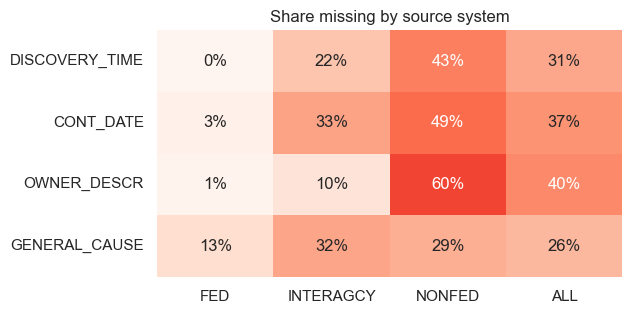

Starter filter (CONT_DATE not null) drops 37.5% of fires
Natural share: 13.4% of all fires vs 18.2% after the filter
FED share:     20.3% of all fires vs 31.5% after the filter


In [4]:
missing = pd.DataFrame({
    'DISCOVERY_TIME': df['DISCOVERY_TIME'].isna(),
    'CONT_DATE': df['CONT_DATE'].isna(),
    'OWNER_DESCR': df['OWNER_DESCR'].eq('MISSING/NOT SPECIFIED'),
    'GENERAL_CAUSE': ~df['CAUSE_KNOWN'],
})
by_source = missing.groupby(df['SOURCE_SYSTEM_TYPE'], observed=True).mean().T
by_source['ALL'] = missing.mean()

plt.figure(figsize=(6, 3.2))
sns.heatmap(by_source, annot=True, fmt='.0%', cmap='Reds', vmin=0, vmax=1, cbar=False)
plt.title('Share missing by source system')
plt.xlabel('')
savefig('missingness.png')
plt.show()

kept = df['CONT_DATE'].notna()
natural = df['CAUSE_CLASS'].eq('Natural')
fed = df['SOURCE_SYSTEM_TYPE'].eq('FED')
print(f'Starter filter (CONT_DATE not null) drops {1 - kept.mean():.1%} of fires')
print(f'Natural share: {natural.mean():.1%} of all fires vs {natural[kept].mean():.1%} after the filter')
print(f'FED share:     {fed.mean():.1%} of all fires vs {fed[kept].mean():.1%} after the filter')

Federal records are nearly complete, but non-federal records are missing about 43% of discovery times, 49% of containment dates and 60% of land owners. So missing values mostly tell us which agency reported the fire.

Dropping rows without a containment date (like the starter does) removes over a third of the data and shifts it toward federal, lightning-caused fires. I keep all rows.

### Reporting changes over time

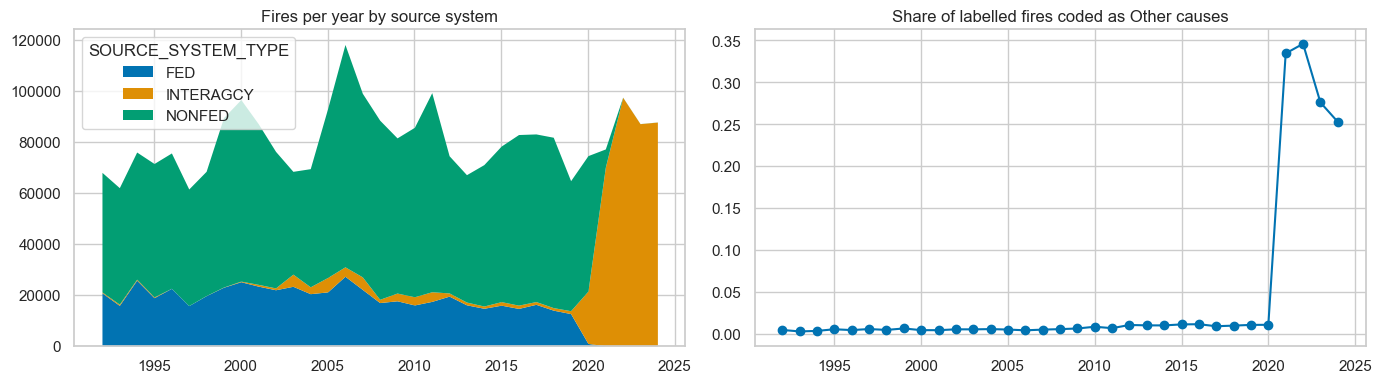

Other causes share by year: {2018: 0.01, 2019: 0.01, 2020: 0.01, 2021: 0.334, 2022: 0.346, 2023: 0.276, 2024: 0.253}


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.crosstab(df['FIRE_YEAR'], df['SOURCE_SYSTEM_TYPE']).plot.area(ax=axes[0], lw=0)
axes[0].set_title('Fires per year by source system')

known = df[df['CAUSE_KNOWN']]
other = known['NWCG_GENERAL_CAUSE'].eq('Other causes').groupby(known['FIRE_YEAR']).mean()
other.plot(ax=axes[1], marker='o')
axes[1].set_title('Share of labelled fires coded as Other causes')
for ax in axes:
    ax.set_xlabel('')
plt.tight_layout()
plt.show()
print('Other causes share by year:', other.loc[2018:].round(3).to_dict())

Two reporting changes happen around 2020-2021:
- After 2020 almost every record is labelled INTERAGCY, so SOURCE_SYSTEM_TYPE basically encodes the year. I won't use it as a feature.
- Starting in 2021, about 30% of labelled fires are coded as Other causes (it was about 1% before). This comes from a few states changing how they code causes, not from fires changing. I'll treat Other causes as unlabelled, the same as Missing.

### Rounded coordinates, times and sizes

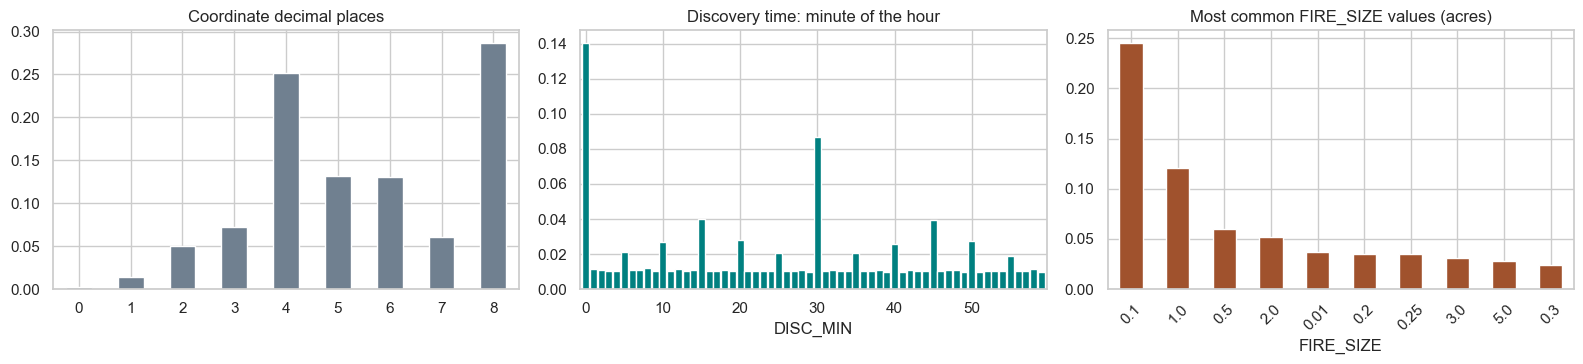

Coordinates with 2 or fewer decimals: 6.7%
Locations shared by 200+ fires: 14 (largest: 571 fires)
Discovery times at :00 or :30: 22.7%
Top 3 size values cover 42.6% of fires


In [6]:
def coord_decimals(x):
    # fewest decimal places that reproduce the stored value
    v = x.to_numpy()
    dec = np.full(len(v), 8)
    for k in range(7, -1, -1):
        dec[np.abs(v - np.round(v, k)) < 1e-9] = k
    return dec


decimals = np.minimum(coord_decimals(df['LATITUDE']), coord_decimals(df['LONGITUDE']))
stack = df.groupby(['LATITUDE', 'LONGITUDE']).size()

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
pd.Series(decimals).value_counts(normalize=True).sort_index().plot.bar(ax=axes[0], color='slategray', rot=0)
axes[0].set_title('Coordinate decimal places')
df['DISC_MIN'].value_counts(normalize=True).sort_index().plot.bar(ax=axes[1], color='teal', width=0.9)
axes[1].set_xticks(range(0, 60, 10))
axes[1].set_xticklabels(range(0, 60, 10), rotation=0)
axes[1].set_title('Discovery time: minute of the hour')
df['FIRE_SIZE'].value_counts(normalize=True).head(10).plot.bar(ax=axes[2], color='sienna', rot=45)
axes[2].set_title('Most common FIRE_SIZE values (acres)')
plt.tight_layout()
plt.show()

round_minute = df['DISC_MIN'].isin([0, 30]).sum() / df['DISC_MIN'].notna().sum()
top3_sizes = df['FIRE_SIZE'].value_counts(normalize=True).head(3).sum()
print(f'Coordinates with 2 or fewer decimals: {(decimals <= 2).mean():.1%}')
print(f'Locations shared by 200+ fires: {(stack >= 200).sum()} (largest: {stack.max()} fires)')
print(f'Discovery times at :00 or :30: {round_minute:.1%}')
print(f'Top 3 size values cover {top3_sizes:.1%} of fires')

- About 7% of coordinates have 2 or fewer decimals (roughly 1 km of uncertainty or worse).
- A few exact points hold hundreds of fires each, mostly Puerto Rico records and agency office locations. These are where fires were reported from, not where they started, so I'll de-duplicate them before clustering.
- Times and sizes are rounded by hand: discovery times pile up on :00 and :30, and 0.1, 1 and 0.5 acres account for over 40% of all fires. Fire size is basically ordinal below 1 acre.

## 2. When do fires happen?

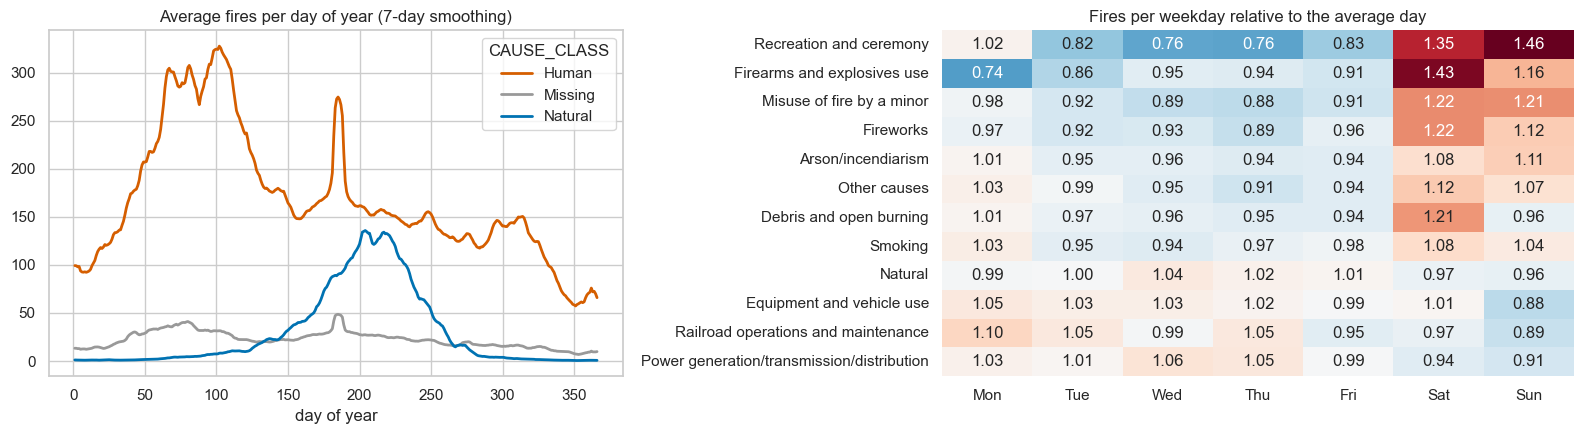

Natural fires in Jun-Aug: 77.8%, human fires in Feb-Apr: 37.3%
Most common discovery hour: {'Human': 14.0, 'Missing': 14.0, 'Natural': 16.0}


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1, 1.1]})

doy = pd.crosstab(df['DISCOVERY_DOY'], df['CAUSE_CLASS']) / df['FIRE_YEAR'].nunique()
doy.rolling(7, center=True, min_periods=1).mean().plot(ax=axes[0], lw=2, color=['#d55e00', '#999999', '#0072b2'])
axes[0].set_title('Average fires per day of year (7-day smoothing)')
axes[0].set_xlabel('day of year')

wk = pd.crosstab(known['NWCG_GENERAL_CAUSE'].astype(str), known['WEEKDAY'])
wk = wk.div(wk.mean(axis=1), axis=0)
wk.columns = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
wk = wk.loc[wk[['Sat', 'Sun']].mean(axis=1).sort_values(ascending=False).index]
sns.heatmap(wk, annot=True, fmt='.2f', cmap='RdBu_r', center=1, cbar=False, ax=axes[1])
axes[1].set_title('Fires per weekday relative to the average day')
axes[1].set_ylabel('')
plt.tight_layout()
savefig('seasonality.png')
plt.show()

human = df['CAUSE_CLASS'].eq('Human')
nat_summer = df.loc[natural, 'MONTH'].isin([6, 7, 8]).mean()
human_spring = df.loc[human, 'MONTH'].isin([2, 3, 4]).mean()
peak_hour = df.dropna(subset=['DISC_HOUR']).groupby('CAUSE_CLASS', observed=True)['DISC_HOUR'].agg(lambda s: s.mode().iat[0])
print(f'Natural fires in Jun-Aug: {nat_summer:.1%}, human fires in Feb-Apr: {human_spring:.1%}')
print('Most common discovery hour:', peak_hour.to_dict())

Human and lightning fires peak at different times of year. Human fires peak in early spring (debris burning before green-up) and spike on July 4. Lightning fires peak in July-August with the thunderstorm season, and they're usually discovered a couple of hours later in the day than human fires.

The weekday heatmap shows a clear weekend effect for people-driven causes (recreation, firearms, kids, fireworks, debris burning). Work-related causes drop on Sunday, and lightning is flat across the week. Season, weekday and hour all differ by cause, so they are useful controls for question 1.

## 3. Where do fires happen?

Hexbin maps of the lower 48 states (plotting 2.6 M points directly is unreadable).

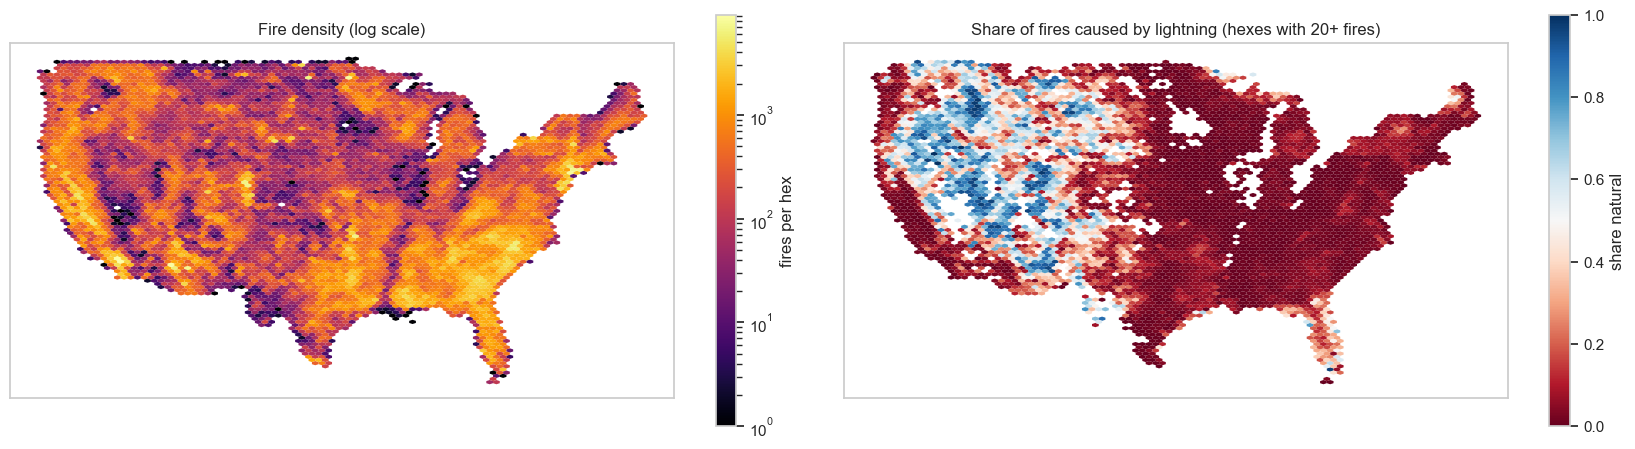

Most acres burned (millions): {'AK': 41.0, 'CA': 25.6, 'ID': 18.1, 'OR': 14.9, 'TX': 14.4}


In [8]:
conus = (df['LONGITUDE'].between(-125, -66) & df['LATITUDE'].between(24, 50)
         & ~df['STATE'].isin(['AK', 'HI', 'PR', 'VI', 'GU']))
c = df.loc[conus, ['LONGITUDE', 'LATITUDE']]
is_natural = natural[conus].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
hb = axes[0].hexbin(c['LONGITUDE'], c['LATITUDE'], gridsize=90, bins='log', mincnt=1, cmap='inferno', linewidths=0)
fig.colorbar(hb, ax=axes[0], shrink=0.8, label='fires per hex')
axes[0].set_title('Fire density (log scale)')
hb = axes[1].hexbin(c['LONGITUDE'], c['LATITUDE'], C=is_natural, reduce_C_function=np.mean, gridsize=90,
                    mincnt=20, cmap='RdBu', vmin=0, vmax=1, linewidths=0)
fig.colorbar(hb, ax=axes[1], shrink=0.8, label='share natural')
axes[1].set_title('Share of fires caused by lightning (hexes with 20+ fires)')
for ax in axes:
    ax.set_aspect(1.25)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

acres_by_state = df.groupby('STATE', observed=True)['FIRE_SIZE'].sum().div(1e6).nlargest(5).round(1)
print('Most acres burned (millions):', acres_by_state.to_dict())

Most fires happen in the East and Southeast, near people. Lightning fires are concentrated in the interior West (NV, ID, MT, OR, AZ, NM), where they're often the majority. East of the Plains, almost every area is under 10% lightning.

Burned area shows the opposite pattern from fire counts: the western states and Alaska burn the most land. Location is clearly an important control for question 1, and the gap between where fires happen and where land burns is what question 2 is about.

## 4. How big do fires get?

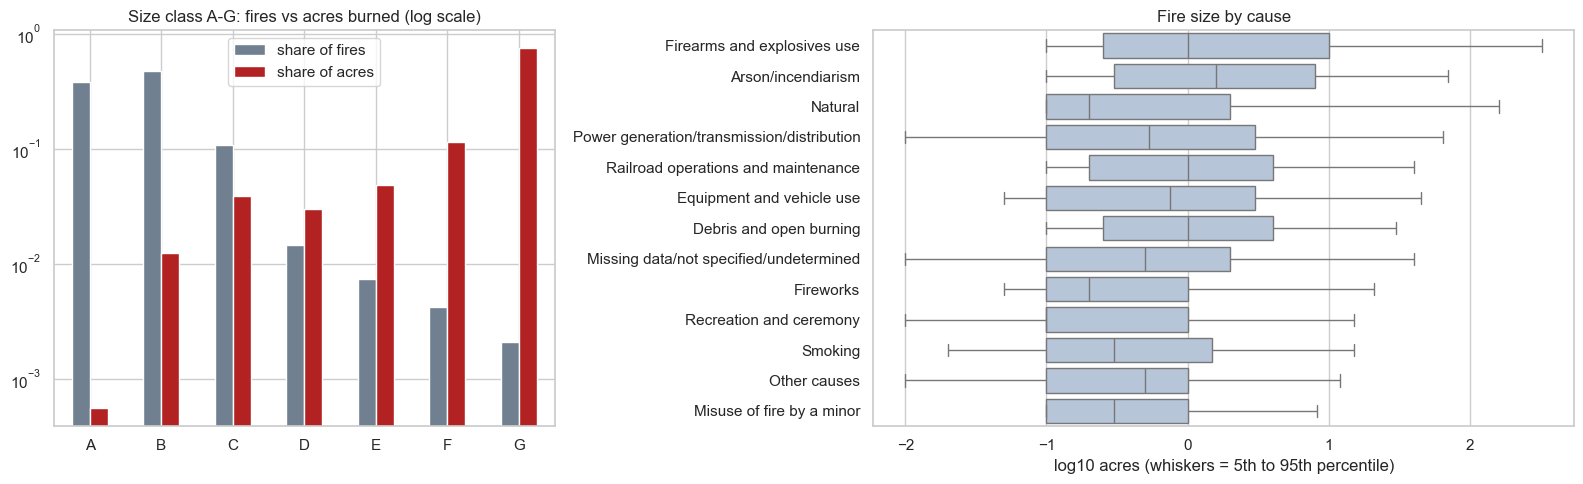

Class G: 0.21% of fires, 75.4% of acres
Lightning: 13.4% of fires, 57.4% of acres


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1, 1.4]})

fire_share = df['FIRE_SIZE_CLASS'].value_counts(normalize=True).sort_index()
acres = df.groupby('FIRE_SIZE_CLASS', observed=True)['FIRE_SIZE'].sum()
acre_share = acres / acres.sum()
pd.DataFrame({'share of fires': fire_share, 'share of acres': acre_share}).plot.bar(
    ax=axes[0], rot=0, logy=True, color=['slategray', 'firebrick'])
axes[0].set_title('Size class A-G: fires vs acres burned (log scale)')
axes[0].set_xlabel('')

order = df.groupby('NWCG_GENERAL_CAUSE', observed=True)['LOG_SIZE'].quantile(0.9).sort_values(ascending=False).index
sns.boxplot(data=df, x='LOG_SIZE', y='NWCG_GENERAL_CAUSE', order=list(order), showfliers=False,
            whis=(5, 95), color='lightsteelblue', ax=axes[1])
axes[1].set_xlabel('log10 acres (whiskers = 5th to 95th percentile)')
axes[1].set_ylabel('')
axes[1].set_title('Fire size by cause')
plt.tight_layout()
savefig('size_skew.png')
plt.show()

g_fires, g_acres = fire_share['G'], acre_share['G']
natural_acres = df.loc[natural, 'FIRE_SIZE'].sum() / df['FIRE_SIZE'].sum()
print(f'Class G: {g_fires:.2%} of fires, {g_acres:.1%} of acres')
print(f'Lightning: {natural.mean():.1%} of fires, {natural_acres:.1%} of acres')

Fire size is extremely skewed. Class G fires (5,000+ acres) are about 0.2% of fires but about 75% of the area burned, while classes A and B are 86% of fires but barely any area. Lightning causes about 13% of fires but over half of all acres burned.

Because of this skew, question 1 predicts a yes/no target (100+ acres, class D and up) instead of raw acres, and question 2 uses log-scaled size features.

# Part B: Fire stations and the two research questions

## 5. Why we need a second dataset

Both questions depend on **where firefighting resources are**, and FPA-FOD does not have that:

- It records where and when each fire started, its final size, containment date, cause, land owner and the reporting agency.
- It has **no locations for fire stations, engines, crews or air bases**. `NWCG_REPORTING_UNIT_NAME` names the reporting office but gives no coordinates, and the exact points that hold hundreds of fires (section 1) are reporting offices, not stations.

So we add the **HIFLD Open Fire and EMS Stations** layer (USGS / DHS), stored in `fire_station_data/` (see its `README.md` for source and license). It gives one point per station, which lets us compute each fire's distance to the nearest station. That distance is the main predictor for question 1, and the coverage gaps for question 2 are defined from it.

Other datasets we considered:

| Dataset | What it adds | Why not now |
|---|---|---|
| HIFLD Hospitals | hospital locations | FPA-FOD has no injuries or evacuations, so there is no outcome to link hospitals to |
| OpenStreetMap `amenity=fire_station` | crowd-sourced stations | used later as a completeness cross-check, not as the main source |
| USFS / BLM / CAL FIRE station lists | wildland stations | no single national download found; noted as a limitation |
| Weather (gridMET), fuels and terrain (LANDFIRE) | controls for fire behaviour | large raster joins; kept as future work |

### Reload the fire table for the two questions

Part A added many derived columns and categorical types. Part B reloads only the columns the two questions need, so its cells do not depend on anything Part A changed. Part A's tables are freed first, since two copies of the 2.66 M-row table do not fit in memory.

In [10]:
import gc

%reset -f out
part_a_tables = [name for name, value in globals().items()
                 if not name.startswith('_') and isinstance(value, (pd.DataFrame, pd.Series, np.ndarray))]
for name in part_a_tables:
    del globals()[name]
plt.close('all')
gc.collect()
print(f'freed {len(part_a_tables)} Part A tables')

Flushing output cache (1 entries)


freed 24 Part A tables

In [11]:
cols = ['FIRE_YEAR', 'DISCOVERY_DATE', 'CONT_DATE', 'FIRE_SIZE', 'FIRE_SIZE_CLASS', 'LATITUDE', 'LONGITUDE',
        'STATE', 'OWNER_DESCR', 'NWCG_CAUSE_CLASSIFICATION', 'NWCG_GENERAL_CAUSE']
with closing(sqlite3.connect(DB_PATH)) as conn:
    df = pd.read_sql_query('SELECT ' + ', '.join(cols) + ' FROM Fires', conn)

df['STATE'] = df['STATE'].str.upper()  # Oklahoma shows up as both 'OK' and 'ok'
df['DATE'] = pd.to_datetime(df['DISCOVERY_DATE'] - JD_EPOCH, unit='D')
df['DOY'] = df['DATE'].dt.dayofyear
df['DURATION_DAYS'] = df['CONT_DATE'] - df['DISCOVERY_DATE']
df['LOG_SIZE'] = np.log10(df['FIRE_SIZE'].clip(lower=0.01))
df['LARGE'] = df['FIRE_SIZE'] >= LARGE_ACRES
df['REGION'] = np.select([df['STATE'].isin(WEST), df['STATE'].eq('AK')], ['West', 'Alaska'], 'East/Other')
df['CONUS'] = ~df['STATE'].isin(NOT_CONUS)
print(f'{len(df):,} fires, {df.FIRE_YEAR.min()}-{df.FIRE_YEAR.max()}')

2,661,383 fires, 1992-2024


## 6. The fire station dataset

In [12]:
with open(STATIONS_PATH, encoding='utf-8') as fh:
    features = json.load(fh)['features']
st = pd.DataFrame([{**f['properties'], 'lon': f['geometry']['coordinates'][0], 'lat': f['geometry']['coordinates'][1]}
                   for f in features])
st['LOAD_YEAR'] = st['LOADDATE'].str[:4].astype(int)

WILDLAND_PATTERN = (r'forest service|usfs|cal ?fire|forestry and fire|bureau of land|\bblm\b|ranger district|'
                    r'wildland|helitack|air ?tanker|state forest')
st['WILDLAND_NAME'] = st['NAME'].str.contains(WILDLAND_PATTERN, case=False, regex=True)

print(f'{len(st):,} stations in {st.STATE.nunique()} states/territories')
print('feature codes:', st['FCODE'].unique(), '| duplicated coordinates:', st.duplicated(['lat', 'lon']).sum(),
      '| missing names:', st['NAME'].isna().sum())
print(f"records loaded {st.LOAD_YEAR.min()}-{st.LOAD_YEAR.max()}, "
      f"{st.LOAD_YEAR.between(2015, 2023).mean():.0%} between 2015 and 2023")
print(f"names that identify a wildland agency: {st.WILDLAND_NAME.sum()} ({st.WILDLAND_NAME.mean():.1%})")
st[['NAME', 'CITY', 'STATE', 'LOADDATE', 'lat', 'lon']].head()

52,057 stations in 56 states/territories
feature codes: [74026] | duplicated coordinates: 7 | missing names: 0
records loaded 2010-2025, 93% between 2015 and 2023
names that identify a wildland agency: 302 (0.6%)


,NAME,CITY,STATE,LOADDATE,lat,lon
0,College Station Fire Department Station 5,College Station,TX,2022-03-13T00:00:00Z,30.567707,-96.249431
1,South Pierce Fire and Rescue Station 84,Eatonville,WA,2023-01-20T00:00:00Z,46.867174,-122.268428
2,Carthage Volunteer Fire Department,Carthage,IN,2022-02-16T00:00:00Z,39.734677,-85.573400
3,Shoreline Fire Department Station 64,Shoreline,WA,2023-02-06T00:00:00Z,47.762885,-122.350273
4,Peoria Fire Department,Peoria,OK,2022-03-13T00:00:00Z,36.915813,-94.673531


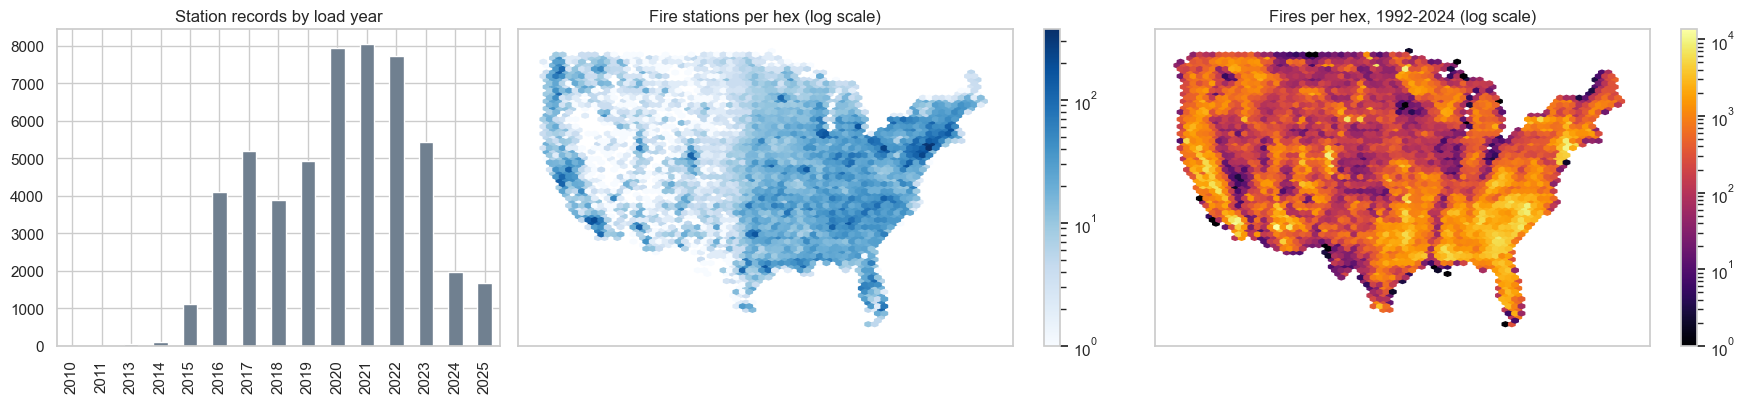

In [13]:
conus_st = st[~st['STATE'].isin(NOT_CONUS) & st['lon'].between(-125, -66) & st['lat'].between(24, 50)]
conus_f = df[df['CONUS'] & df['LONGITUDE'].between(-125, -66) & df['LATITUDE'].between(24, 50)]
extent = (-125, -66, 24, 50)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), gridspec_kw={'width_ratios': [1, 1.4, 1.4]})
st['LOAD_YEAR'].value_counts().sort_index().plot.bar(ax=axes[0], color='slategray')
axes[0].set_title('Station records by load year')
axes[0].set_xlabel('')
hb = axes[1].hexbin(conus_st.lon, conus_st.lat, gridsize=70, bins='log', cmap='Blues', extent=extent, mincnt=1)
axes[1].set_title('Fire stations per hex (log scale)')
fig.colorbar(hb, ax=axes[1])
hb = axes[2].hexbin(conus_f.LONGITUDE, conus_f.LATITUDE, gridsize=70, bins='log', cmap='inferno', extent=extent, mincnt=1)
axes[2].set_title('Fires per hex, 1992-2024 (log scale)')
fig.colorbar(hb, ax=axes[2])
for ax in axes[1:]:
    ax.set_xticks([]), ax.set_yticks([])
plt.tight_layout()
savefig('stations_vs_fires.png')
plt.show()

- **52,057 stations**, all with feature code 74026 (fire/EMS station), no missing names and only 7 duplicated coordinates. The table is clean enough to use as is.
- **93 % of records were loaded in 2015-2023.** It is a snapshot of today's stations, not a history, so a 1995 fire is matched against stations that may not have existed then. We check the main result on 2015-2024 fires separately (section 8).
- **Only 302 names (0.6 %) identify a wildland agency** (CAL FIRE, Forest Service, BLM, state forestry). The layer is mostly municipal and county stations, so federal wildland crews are under-represented.
- **The two maps do not line up.** Stations are dense in the East and along the West Coast and sparse across the interior West, the northern Plains and south Texas, yet those areas still have many fires. That mismatch is what both research questions are about.

## 7. Joining fires to stations

For every fire we find the nearest station with a haversine `BallTree` (great-circle distance, so no map projection is needed). The coordinate issues from section 1 carry over: about 7 % of fires have coordinates rounded to 2 or fewer decimals (around 1 km of error or worse), which is small next to the distances below.

In [14]:
tree = BallTree(np.radians(st[['lat', 'lon']].to_numpy()), metric='haversine')
dist, _ = tree.query(np.radians(df[['LATITUDE', 'LONGITUDE']].to_numpy()), k=1)
df['DIST_KM'] = dist[:, 0] * EARTH_KM

BANDS = [0, 2, 5, 10, 20, 40, np.inf]
BAND_LABELS = ['0-2', '2-5', '5-10', '10-20', '20-40', '40+']
df['DIST_BAND'] = pd.cut(df['DIST_KM'], BANDS, labels=BAND_LABELS, right=False)

display(df['DIST_KM'].describe(percentiles=[.1, .25, .5, .75, .9, .99]).to_frame('km').T.round(2))
display(df.groupby('REGION')['DIST_KM'].median().round(1).to_frame('median km'))

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
km,2661383.0,6.47,7.74,0.0,1.1,2.17,4.19,7.45,13.88,39.01,191.27


,median km
REGION,
Alaska,9.2
East/Other,3.9
West,5.7


### Two extra columns: stations within 25 km, and stacked locations

- **Stations within 25 km** (`STATIONS_25KM`) is a second measure of how much help is nearby. The nearest distance says how far the first engine is; the count says whether more can follow.
- **Stacked locations** are exact coordinates shared by 200+ fires. Section 1 showed these are reporting offices and placeholders, not ignition points, so the odds-ratio analysis in section 8 leaves them out.

In [15]:
STACK_MIN = 200   # an exact coordinate shared by this many fires = office / placeholder location


def to_xyz(lat, lon):
    # points on the unit sphere, so a k-d tree can count stations within a great-circle radius quickly
    la, lo = np.radians(lat), np.radians(lon)
    return np.column_stack([np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)])


def km_to_chord(km):
    return 2 * np.sin(km / (2 * EARTH_KM))


st_tree = cKDTree(to_xyz(st['lat'].to_numpy(), st['lon'].to_numpy()))
df['STATIONS_25KM'] = st_tree.query_ball_point(to_xyz(df['LATITUDE'].to_numpy(), df['LONGITUDE'].to_numpy()),
                                               r=km_to_chord(25), return_length=True, workers=-1)
df['STACKED'] = df.groupby(['LATITUDE', 'LONGITUDE'])['FIRE_YEAR'].transform('size') >= STACK_MIN
print('stations within 25 km, quantiles:', df['STATIONS_25KM'].quantile([.05, .25, .5, .75, .95]).to_dict())
print(f"fires with no station within 25 km: {df['STATIONS_25KM'].eq(0).mean():.1%}")
print(f"fires on stacked locations ({STACK_MIN}+ fires at one exact point): {df['STACKED'].sum():,}")

stations within 25 km, quantiles: {0.05: 1.0, 0.25: 7.0, 0.5: 16.0, 0.75: 27.0, 0.95: 80.0}
fires with no station within 25 km: 3.7%
fires on stacked locations (200+ fires at one exact point): 4,219


- The median fire has **16 stations within 25 km**; 5 % have one or none, and **3.7 % have no station within 25 km at all**.
- **4,219 fires sit on stacked locations** (200+ fires at one exact point, mostly office and placeholder coordinates). That is under 0.2 % of fires, so leaving them out changes little, but it removes points whose distance means nothing.

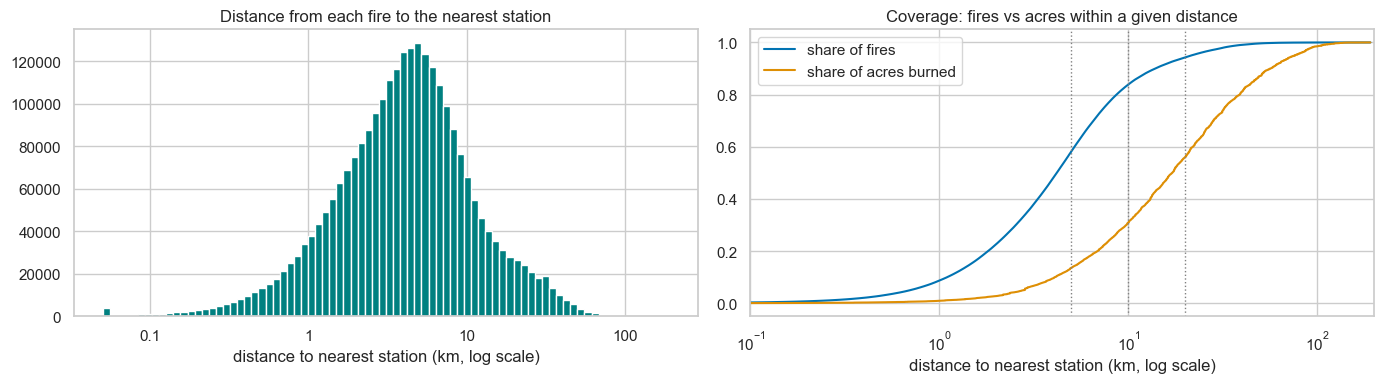

within  5 km: 58.2% of fires, 13.6% of acres
within 10 km: 83.8% of fires, 30.9% of acres
within 20 km: 94.3% of fires, 56.0% of acres


In [16]:
order = np.argsort(df['DIST_KM'].to_numpy())
d_sorted = df['DIST_KM'].to_numpy()[order]
cum_fires = np.arange(1, len(order) + 1) / len(order)
cum_acres = np.cumsum(df['FIRE_SIZE'].to_numpy()[order]) / df['FIRE_SIZE'].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(np.log10(df['DIST_KM'].clip(lower=0.05)), bins=80, color='teal')
axes[0].set_xticks(np.log10([0.1, 1, 10, 100]), ['0.1', '1', '10', '100'])
axes[0].set_xlabel('distance to nearest station (km, log scale)')
axes[0].set_title('Distance from each fire to the nearest station')
axes[1].plot(d_sorted, cum_fires, label='share of fires')
axes[1].plot(d_sorted, cum_acres, label='share of acres burned')
for km in (5, 10, 20):
    axes[1].axvline(km, color='gray', ls=':', lw=1)
axes[1].set_xscale('log')
axes[1].set_xlim(0.1, 200)
axes[1].set_xlabel('distance to nearest station (km, log scale)')
axes[1].set_title('Coverage: fires vs acres within a given distance')
axes[1].legend()
plt.tight_layout()
savefig('distance_coverage.png')
plt.show()

for km in (5, 10, 20):
    near = df['DIST_KM'] < km
    print(f'within {km:>2} km: {near.mean():.1%} of fires, '
          f"{df.loc[near, 'FIRE_SIZE'].sum() / df['FIRE_SIZE'].sum():.1%} of acres")

- The median fire starts **4.2 km** from a station, 90 % start within 13.9 km and 99 % within 39 km. Medians: East 3.9 km, West 5.7 km, Alaska 9.2 km.
- **Coverage of fires and coverage of burned land are very different.** 58 % of fires start within 5 km of a station but those fires account for only 14 % of acres; within 10 km it is 84 % of fires but 31 % of acres. The gap between the two curves is the burned area that comes from the small share of fires far from any station.

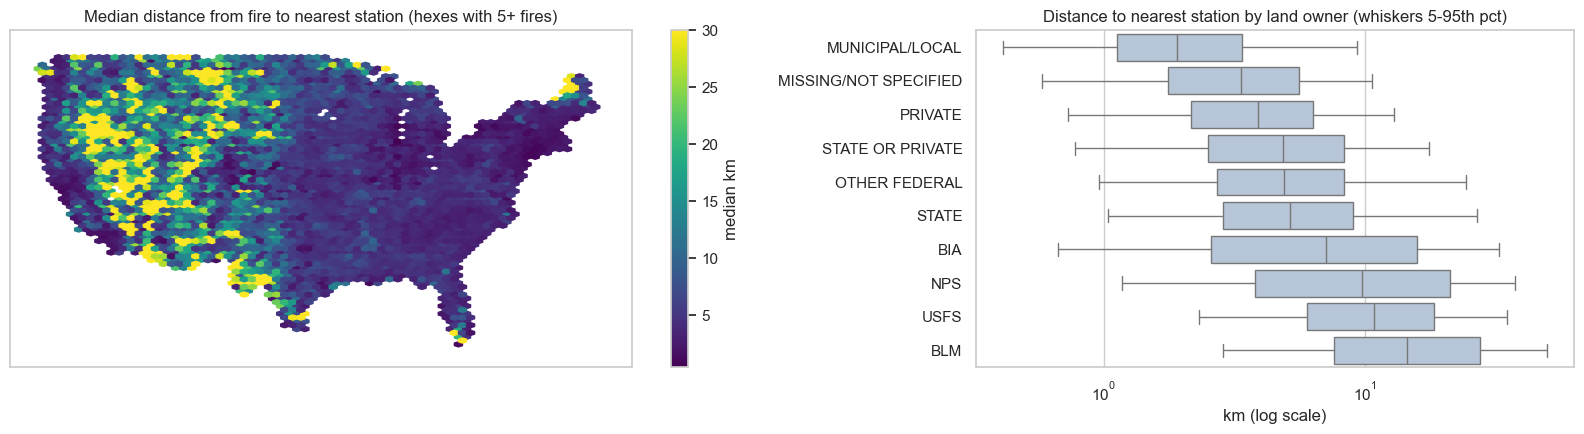

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1.3, 1]})
hb = axes[0].hexbin(conus_f.LONGITUDE, conus_f.LATITUDE, C=df.loc[conus_f.index, 'DIST_KM'],
                    reduce_C_function=np.median, gridsize=70, cmap='viridis', vmax=30, extent=extent, mincnt=5)
fig.colorbar(hb, ax=axes[0], label='median km')
axes[0].set_title('Median distance from fire to nearest station (hexes with 5+ fires)')
axes[0].set_xticks([]), axes[0].set_yticks([])

owners = df['OWNER_DESCR'].value_counts().index[:10]
sub = df[df['OWNER_DESCR'].isin(owners)]
order_o = sub.groupby('OWNER_DESCR')['DIST_KM'].median().sort_values().index
sns.boxplot(data=sub, y='OWNER_DESCR', x='DIST_KM', order=order_o, ax=axes[1], showfliers=False,
            whis=(5, 95), color='lightsteelblue', log_scale=True)
axes[1].set_title('Distance to nearest station by land owner (whiskers 5-95th pct)')
axes[1].set_ylabel('')
axes[1].set_xlabel('km (log scale)')
plt.tight_layout()
savefig('distance_map_owner.png')
plt.show()

- Far-from-station fires sit in the interior West (Great Basin, Montana, Wyoming), the northern Plains, south Texas and the Everglades.
- By land owner the median distance goes from 1.9 km (municipal) and 3.9 km (private) up to 10.8 km (USFS) and 14.5 km (BLM).
- **Part of that is a data gap, not a real gap.** Federal land is protected by wildland engines and crews that are mostly missing from this layer, so `DIST_KM` means "distance to the nearest structural fire station", not "distance to any firefighting resource". We keep land owner as a predictor so the model can learn this offset, and we state it as a limitation.

## 8. Question 1: does distance to a station change fire outcomes?

**Target:** `LARGE` = final size of 100 acres or more (size class D-G). We use a binary target instead of raw acres because section 1 showed sizes are rounded by hand below 1 acre and extremely skewed. Containment time is a secondary outcome, since `CONT_DATE` is missing for about 37 % of fires.

In [18]:
split = np.where(df['FIRE_YEAR'] < SPLIT_YEAR, 'train 1992-2018', 'test 2019-2024')
summary = df.groupby(split).agg(fires=('LARGE', 'size'), large=('LARGE', 'sum'), share_large=('LARGE', 'mean'),
                                cont_date_known=('CONT_DATE', lambda s: s.notna().mean()))
display(summary.style.format({'fires': '{:,}', 'large': '{:,}', 'share_large': '{:.2%}', 'cont_date_known': '{:.0%}'}))
print(f"imbalance: about 1 large fire for every {1 / df['LARGE'].mean() - 1:.0f} small ones")

,fires,large,share_large,cont_date_known
test 2019-2024,"488,613","12,382",2.53%,72%
train 1992-2018,"2,172,770","63,207",2.91%,60%


imbalance: about 1 large fire for every 34 small ones


,fires,large,share_large,share_of_acres,lightning_share,mean_days_to_contain
DIST_BAND,,,,,,
0-2,"602,152","4,505",0.75%,2.7%,3.4%,0.30
2-5,"946,940","16,495",1.74%,10.9%,5.8%,0.39
5-10,"682,126","23,268",3.41%,17.3%,12.4%,0.61
10-20,"278,161","16,966",6.10%,25.1%,37.0%,1.54
20-40,"127,730","10,254",8.03%,25.2%,58.4%,2.89
40+,"24,274","4,101",16.89%,18.8%,79.9%,8.47


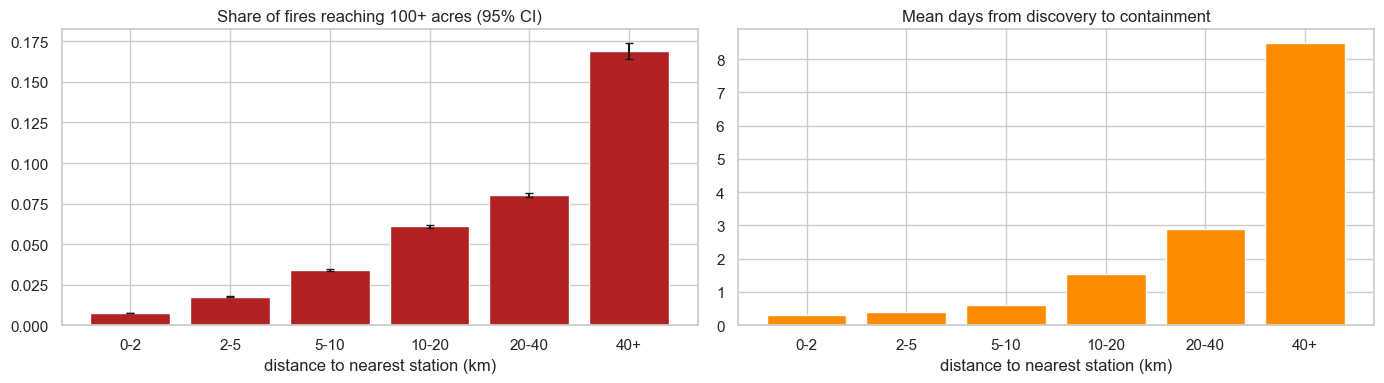

In [19]:
def wilson(k, n, z=1.96):
    # 95% Wilson score interval for a proportion
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


g = df.groupby('DIST_BAND', observed=True)
bands = pd.DataFrame({'fires': g.size(), 'large': g['LARGE'].sum()})
bands['share_large'] = bands['large'] / bands['fires']
bands['lo'], bands['hi'] = wilson(bands['large'], bands['fires'])
bands['share_of_acres'] = g['FIRE_SIZE'].sum() / df['FIRE_SIZE'].sum()
bands['lightning_share'] = g['NWCG_CAUSE_CLASSIFICATION'].apply(lambda c: c.eq('Natural').mean())
bands['mean_days_to_contain'] = g['DURATION_DAYS'].mean()
display(bands.drop(columns=['lo', 'hi']).style.format({'fires': '{:,}', 'large': '{:,}', 'share_large': '{:.2%}',
                                                         'share_of_acres': '{:.1%}', 'lightning_share': '{:.1%}',
                                                         'mean_days_to_contain': '{:.2f}'}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(bands))
axes[0].bar(x, bands['share_large'], color='firebrick',
            yerr=[bands['share_large'] - bands['lo'], bands['hi'] - bands['share_large']], capsize=3)
axes[0].set_xticks(x, bands.index)
axes[0].set_xlabel('distance to nearest station (km)')
axes[0].set_title(f'Share of fires reaching {LARGE_ACRES}+ acres (95% CI)')
axes[1].bar(x, bands['mean_days_to_contain'], color='darkorange')
axes[1].set_xticks(x, bands.index)
axes[1].set_xlabel('distance to nearest station (km)')
axes[1].set_title('Mean days from discovery to containment')
plt.tight_layout()
savefig('large_by_distance.png')
plt.show()

- **The share of fires that reach 100+ acres rises steadily with distance:** 0.75 % (0-2 km), 1.7 %, 3.4 %, 6.1 %, 8.0 %, and **16.9 % beyond 40 km**, about 22 times higher. With hundreds of thousands of fires per band the confidence intervals are tiny.
- Mean time to containment rises from 0.3 to 8.5 days (fires with a containment date only).
- **But the lightning share also climbs from 3 % to 80 %.** Far-away fires are a different mix of fires, so the trend could partly be that mix. The next plot checks this.

### Is it just that far-away fires are lightning fires in the West?

Remote fires differ in more than distance: they are more often lightning-caused and in western fuels and terrain. If the trend were only that mix, it would disappear inside each cause and region. We also repeat it for 2015-2024, when the station snapshot is closest to the fire dates.

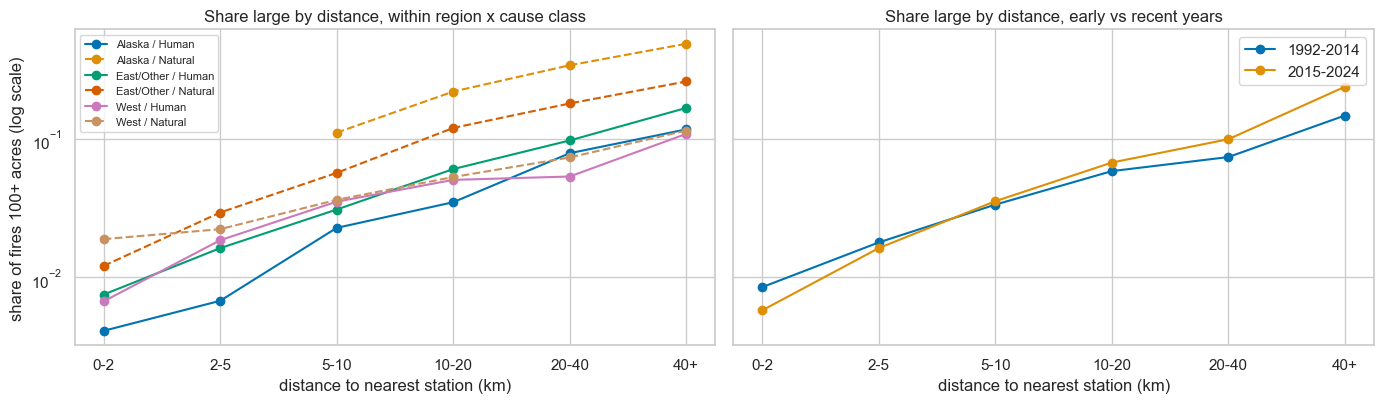

In [20]:
known = df[df['NWCG_CAUSE_CLASSIFICATION'].isin(['Human', 'Natural'])]
strata = (known.groupby(['REGION', 'NWCG_CAUSE_CLASSIFICATION', 'DIST_BAND'], observed=True)['LARGE']
          .agg(['mean', 'size']).reset_index())
strata = strata[strata['size'] >= 200]  # hide noisy cells

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for (region, cause), s in strata.groupby(['REGION', 'NWCG_CAUSE_CLASSIFICATION']):
    axes[0].plot(s['DIST_BAND'].astype(str), s['mean'], marker='o',
                 ls='-' if cause == 'Human' else '--', label=f'{region} / {cause}')
axes[0].set_title('Share large by distance, within region x cause class')
axes[0].legend(fontsize=8)
for label, mask in [('1992-2014', df['FIRE_YEAR'] < 2015), ('2015-2024', df['FIRE_YEAR'] >= 2015)]:
    r = df[mask].groupby('DIST_BAND', observed=True)['LARGE'].mean()
    axes[1].plot(r.index.astype(str), r.values, marker='o', label=label)
axes[1].set_title('Share large by distance, early vs recent years')
axes[1].legend()
for ax in axes:
    ax.set_yscale('log')
    ax.set_xlabel('distance to nearest station (km)')
axes[0].set_ylabel(f'share of fires {LARGE_ACRES}+ acres (log scale)')
plt.tight_layout()
savefig('large_by_distance_strata.png')
plt.show()
display(strata.pivot_table(index='DIST_BAND', columns=['REGION', 'NWCG_CAUSE_CLASSIFICATION'], values='mean',
                           observed=True).style.format('{:.2%}', na_rep='-'))

- **The trend holds in every region x cause group.** Human-caused fires in the East go from 0.75 % to 16.8 % large, in the West from 0.67 % to 10.9 %; lightning fires in the East go from 1.2 % to 26 %, in Alaska from 11 % to 49 %. So it is not just "far fires are lightning fires".
- The flattest line is **western lightning fires** (1.9 % to 11.5 %). These burn mostly on federal land, where wildland crews that are not in the station layer do the initial attack, which fits the data-gap note above.
- **1992-2014 and 2015-2024 give almost the same curve**, so using today's station list for older fires is not what drives the result.
- It is still an association. Remote places also differ in fuel, terrain and how late fires are discovered, and FPA-FOD has none of those. Milestone 2 reports it that way and uses the model to compare otherwise similar fires.

### How strong is the effect? Odds ratios per doubling of distance

The bands show *that* the share of large fires rises; an odds ratio puts one number on *how fast*. We fit a logistic regression of `LARGE` on log2(distance + 1 km), so the coefficient is the odds multiplier for each doubling of (distance + 1 km). We fit it inside each region, land-owner group and cause class, then on all fires with controls for state, owner, month and year (and cause).

This uses lower-48 fires and leaves out the stacked office locations. Each fit uses a fixed random sample of 300 k fires to keep run time down. The 95 % Wald intervals treat every fire as independent; neighbouring fires are not, so the true intervals are wider. Read them as effect sizes, not significance tests.

In [21]:
REGION6 = {**dict.fromkeys(['CA', 'OR', 'WA'], 'Pacific'),
           **dict.fromkeys(['ID', 'NV', 'UT', 'MT', 'WY', 'CO'], 'Mountain West'),
           **dict.fromkeys(['AZ', 'NM'], 'Southwest'),
           **dict.fromkeys(['TX', 'OK', 'KS', 'NE', 'SD', 'ND'], 'Plains'),
           **dict.fromkeys(['AL', 'AR', 'FL', 'GA', 'KY', 'LA', 'MS', 'NC', 'SC', 'TN', 'VA', 'WV'], 'Southeast')}
OR_SAMPLE = 300_000
CAUSE_MISSING = 'Missing data/not specified/undetermined'

in_box = df['LONGITUDE'].between(-125, -66) & df['LATITUDE'].between(24, 50)
A = df.loc[df['CONUS'] & in_box & ~df['STACKED'],
           ['FIRE_YEAR', 'DATE', 'FIRE_SIZE', 'FIRE_SIZE_CLASS', 'LATITUDE', 'LONGITUDE', 'STATE', 'OWNER_DESCR',
            'NWCG_CAUSE_CLASSIFICATION', 'DIST_KM', 'LARGE']].copy()
A['LARGE'] = A['LARGE'].astype(int)
A['LOG2_DIST'] = np.log2(A['DIST_KM'] + 1)   # one unit = one doubling of (distance + 1 km)
A['REGION6'] = A['STATE'].map(REGION6).fillna('North/East')
top_owners = A['OWNER_DESCR'].value_counts().index[:7]
A['OWNER_GRP'] = A['OWNER_DESCR'].where(A['OWNER_DESCR'].isin(top_owners), 'OTHER')
A['CAUSE'] = A['NWCG_CAUSE_CLASSIFICATION'].replace({CAUSE_MISSING: 'Missing'})
A['MONTH'] = A['DATE'].dt.month.astype(str)
A['YEAR10'] = (A['FIRE_YEAR'] - 2008) / 10
for t in (10, 100, 1000):
    A[f'LARGE_{t}'] = (A['FIRE_SIZE'] >= t).astype(int)
A = A.drop(columns=['DATE', 'OWNER_DESCR', 'NWCG_CAUSE_CLASSIFICATION'])
print(f'{len(A):,} lower-48 fires off stacked locations; {A.LARGE.mean():.2%} are large')


def odds_ratio(frame, target='LARGE', cats=(), nums=(), n=OR_SAMPLE):
    # logistic regression of target on log2 distance (+ controls): odds ratio per doubling with a 95% Wald interval
    s = frame.sample(min(n, len(frame)), random_state=SEED)
    y = s[target].to_numpy()
    if min(y.sum(), len(y) - y.sum()) < 50:
        return {'OR_per_doubling': np.nan, 'ci_low': np.nan, 'ci_high': np.nan, 'n': len(y)}
    parts = [s[['LOG2_DIST']] - s['LOG2_DIST'].mean(), s[list(nums)]]
    if cats:
        parts.append(pd.get_dummies(s[list(cats)], drop_first=True))
    X_ = pd.concat(parts, axis=1).to_numpy(dtype=float)
    m = LogisticRegression(penalty=None, max_iter=2000).fit(X_, y)
    p = m.predict_proba(X_)[:, 1]
    Xd = np.column_stack([np.ones(len(X_)), X_])
    cov = np.linalg.pinv((Xd * (p * (1 - p))[:, None]).T @ Xd)
    b, se = m.coef_[0, 0], np.sqrt(cov[1, 1])
    return {'OR_per_doubling': np.exp(b), 'ci_low': np.exp(b - 1.96 * se), 'ci_high': np.exp(b + 1.96 * se), 'n': len(y)}

2,603,776 lower-48 fires off stacked locations; 2.78% are large


#### Does it depend on the size cutoff? And do tiny fires go missing far from stations?

If remote fires were simply under-reported when small, the share of large fires would rise with distance even if distance did nothing. Two checks: repeat the curve for 10 and 1,000 acres, and look at the share of tiny class A fires (0.25 acre or less) by distance.

>=    10 acres: 4.56% in the nearest bin vs 17.35% in the farthest (3.8x)


>=   100 acres: 0.64% in the nearest bin vs 8.43% in the farthest (13.1x)


>= 1,000 acres: 0.10% in the nearest bin vs 3.12% in the farthest (32.8x)


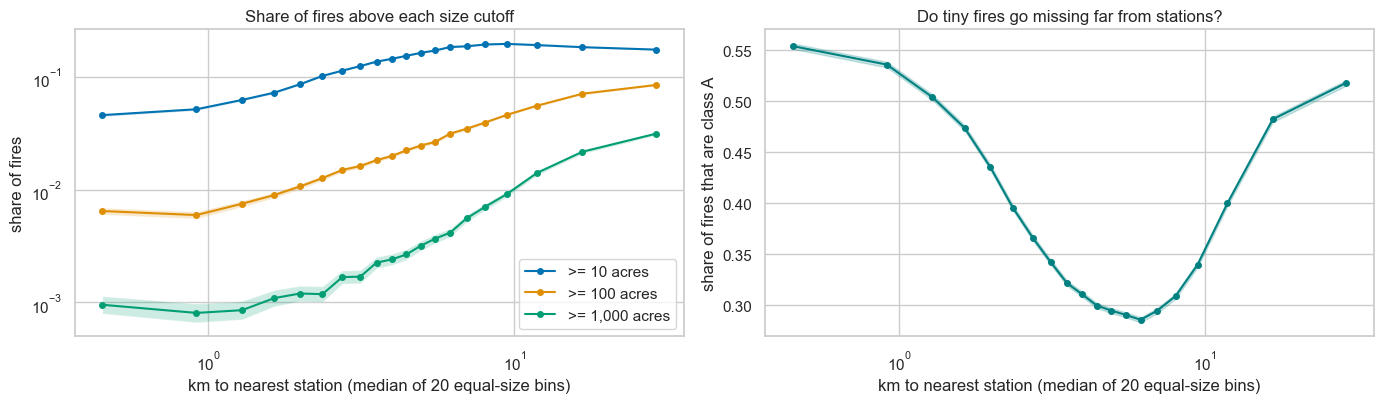

class A share: 55.4% in the nearest bin, lowest 28.6% at 6.2 km, 51.8% in the farthest bin


In [22]:
def share_curve(frame, flag, nbins=20):
    # share of fires with `flag` in equal-count distance bins, with 95% Wilson intervals
    b = pd.qcut(frame['DIST_KM'], nbins, duplicates='drop')
    t = (pd.DataFrame({'d': frame['DIST_KM'], 'f': flag.astype(float)}).groupby(b, observed=True)
         .agg(dist=('d', 'median'), n=('f', 'size'), k=('f', 'sum')))
    t['p'] = t['k'] / t['n']
    t['lo'], t['hi'] = wilson(t['k'], t['n'])
    return t


fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for t in (10, 100, 1000):
    cv = share_curve(A, A[f'LARGE_{t}'])
    axes[0].plot(cv['dist'], cv['p'], marker='o', ms=4, label=f'>= {t:,} acres')
    axes[0].fill_between(cv['dist'], cv['lo'], cv['hi'], alpha=0.2)
    print(f'>= {t:>5,} acres: {cv.p.iloc[0]:.2%} in the nearest bin vs {cv.p.iloc[-1]:.2%} in the farthest '
          f'({cv.p.iloc[-1] / cv.p.iloc[0]:.1f}x)')
axes[0].set(xscale='log', yscale='log', xlabel='km to nearest station (median of 20 equal-size bins)',
            ylabel='share of fires', title='Share of fires above each size cutoff')
axes[0].legend()

cv_a = share_curve(A, A['FIRE_SIZE_CLASS'].eq('A'))
axes[1].plot(cv_a['dist'], cv_a['p'], marker='o', ms=4, color='teal')
axes[1].fill_between(cv_a['dist'], cv_a['lo'], cv_a['hi'], alpha=0.2, color='teal')
axes[1].set(xscale='log', xlabel='km to nearest station (median of 20 equal-size bins)',
            ylabel='share of fires that are class A', title='Do tiny fires go missing far from stations?')
plt.tight_layout()
savefig('size_cutoffs.png')
plt.show()
print(f"class A share: {cv_a.p.iloc[0]:.1%} in the nearest bin, lowest {cv_a.p.min():.1%} at "
      f"{cv_a.dist[cv_a.p.idxmin()]:.1f} km, {cv_a.p.iloc[-1]:.1%} in the farthest bin")

- **The steeper the size cutoff, the steeper the rise.** From the nearest to the farthest of 20 equal-size distance bins, fires of 10+ acres go from 4.6 % to 17.4 % (3.8x), 100+ acres from 0.64 % to 8.4 % (13x) and 1,000+ acres from 0.10 % to 3.1 % (33x). Distance matters most for the fires that really get away.
- **Tiny fires do not vanish far from stations.** The class A share is 55 % in the nearest bin, drops to 29 % around 6 km, then climbs back to 52 % in the farthest bin. If small remote fires simply went unreported, the far end would have few class A fires; it has plenty. So under-reporting cannot explain the trend.
- The U shape is itself interesting: the near end is towns, where local departments log many small grass and debris fires; the far end is federal land, where agencies report every lightning start. That is a guess we have not tested.

#### Inside each group

odds ratio above 1 (whole 95% interval) in 17 of 17 groups, range 1.26-2.77


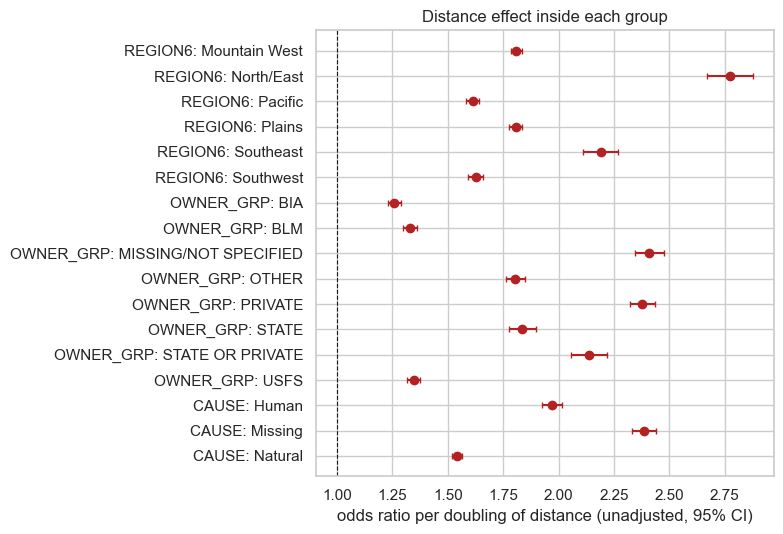

In [23]:
rows = []
for col in ['REGION6', 'OWNER_GRP', 'CAUSE']:
    for level, sub in A.groupby(col):
        rows.append({'split': col, 'level': level, 'fires': len(sub), 'share_large': sub['LARGE'].mean(),
                     'median_km': sub['DIST_KM'].median(), **odds_ratio(sub)})
or_strata = pd.DataFrame(rows).set_index(['split', 'level']).drop(columns='n')
print(f"odds ratio above 1 (whole 95% interval) in {(or_strata['ci_low'] > 1).sum()} of {len(or_strata)} groups, "
      f"range {or_strata.OR_per_doubling.min():.2f}-{or_strata.OR_per_doubling.max():.2f}")

fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(or_strata))
ax.errorbar(or_strata['OR_per_doubling'], y, fmt='o', color='firebrick', capsize=2,
            xerr=[or_strata['OR_per_doubling'] - or_strata['ci_low'], or_strata['ci_high'] - or_strata['OR_per_doubling']])
ax.axvline(1, color='k', lw=0.8, ls='--')
ax.set_yticks(y, [f'{s}: {l}' for s, l in or_strata.index])
ax.invert_yaxis()
ax.set_xlabel('odds ratio per doubling of distance (unadjusted, 95% CI)')
ax.set_title('Distance effect inside each group')
plt.tight_layout()
savefig('or_by_group.png')
plt.show()
display(or_strata.style.format({'fires': '{:,}', 'share_large': '{:.2%}', 'median_km': '{:.1f}',
                                'OR_per_doubling': '{:.2f}', 'ci_low': '{:.2f}', 'ci_high': '{:.2f}'}))

- **The odds ratio is above 1 in all 17 groups** (6 regions, 8 owner groups, 3 cause classes), from 1.26 to 2.77, and every 95 % interval sits above 1. No single region or owner drives the result.
- **It is weakest on federal land:** BIA 1.26, BLM 1.33, USFS 1.35, and lightning fires 1.54. These are the places where wildland crews that are not in the station layer do the initial attack, and where terrain and fuels matter more, which matches the data-gap note in section 7.
- **It is strongest in the North/East (2.77) and Southeast (2.19)**, and on private land and fires with no owner listed (about 2.4), where municipal and county stations are the actual first responders.

#### Adjusted estimate

In [24]:
CTRL = ['STATE', 'OWNER_GRP', 'MONTH']
SPECS = {'unadjusted': {},
         '+ state, owner, month, year': dict(cats=CTRL, nums=['YEAR10']),
         '+ cause class': dict(cats=CTRL + ['CAUSE'], nums=['YEAR10'])}
or_adjusted = pd.DataFrame({name: odds_ratio(A, **spec) for name, spec in SPECS.items()}).T
display(or_adjusted.drop(columns='n').round(3))

# does the answer depend on how "large" is defined?
or_cutoff = pd.DataFrame({f'>= {t:,} acres': odds_ratio(A, target=f'LARGE_{t}', **SPECS['+ state, owner, month, year'])
                          for t in (10, 100, 1000)}).T
display(or_cutoff.drop(columns='n').round(3))
raw, adj = or_adjusted.loc['unadjusted'], or_adjusted.loc['+ state, owner, month, year']
print(f'share of the raw excess odds left after adjustment: '
      f'{(adj.OR_per_doubling - 1) / (raw.OR_per_doubling - 1):.0%}')

,OR_per_doubling,ci_low,ci_high
unadjusted,1.896,1.862,1.932
"+ state, owner, month, year",1.799,1.756,1.844
+ cause class,1.788,1.743,1.833


,OR_per_doubling,ci_low,ci_high
>= 10 acres,1.547,1.528,1.568
>= 100 acres,1.799,1.756,1.844
">= 1,000 acres",2.073,1.970,2.182


share of the raw excess odds left after adjustment: 89%


- Each doubling of (distance + 1 km) multiplies the odds of a large fire by **1.90 unadjusted** and **1.80 after adjusting for state, land owner, month and year** [1.76, 1.84]. Adding cause barely moves it (1.79). **About 89 % of the raw excess odds survives adjustment.**
- The adjusted effect grows with the cutoff: **1.55 for 10 acres, 1.80 for 100 and 2.07 for 1,000.** That is the pattern expected if distance matters most for fires that escape initial attack.
- Fuels, terrain, weather and detection delay are not in the data, so this is still an association. The intervals are too narrow because neighbouring fires are not independent.

### Is the effect stable over time?

,OR_per_doubling,ci_low,ci_high
1992-2018,1.765,1.722,1.809
2019-2024,2.030,1.977,2.084


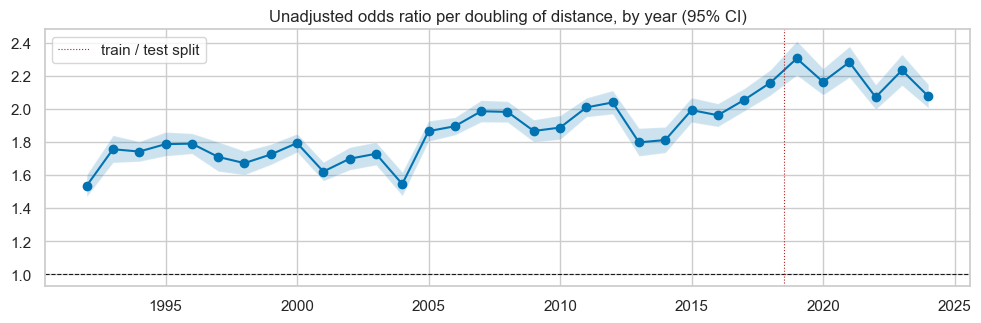

yearly odds ratio above 1 (whole interval) in 33 of 33 years; range 1.53-2.30


In [25]:
adj_cats = SPECS['+ state, owner, month, year']['cats']
or_period = pd.DataFrame({
    f'1992-{SPLIT_YEAR - 1}': odds_ratio(A[A['FIRE_YEAR'] < SPLIT_YEAR], cats=adj_cats),
    f'{SPLIT_YEAR}-2024': odds_ratio(A[A['FIRE_YEAR'] >= SPLIT_YEAR], cats=adj_cats)}).T
display(or_period.drop(columns='n').round(3))

or_yearly = pd.DataFrame({yr: odds_ratio(sub, n=100_000) for yr, sub in A.groupby('FIRE_YEAR')}).T
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(or_yearly.index, or_yearly['OR_per_doubling'], marker='o')
ax.fill_between(or_yearly.index, or_yearly['ci_low'], or_yearly['ci_high'], alpha=0.2)
ax.axhline(1, color='k', lw=0.8, ls='--')
ax.axvline(SPLIT_YEAR - 0.5, color='firebrick', lw=0.8, ls=':', label='train / test split')
ax.set_title('Unadjusted odds ratio per doubling of distance, by year (95% CI)')
ax.legend()
plt.tight_layout()
savefig('or_by_year.png')
plt.show()
print(f"yearly odds ratio above 1 (whole interval) in {(or_yearly['ci_low'] > 1).sum()} of {len(or_yearly)} years; "
      f"range {or_yearly.OR_per_doubling.min():.2f}-{or_yearly.OR_per_doubling.max():.2f}")

- **The effect is positive in all 33 years** (yearly unadjusted odds ratio 1.53 to 2.30, every interval above 1).
- It is **larger in recent years: 1.77 for 1992-2018 and 2.03 for 2019-2024** (adjusted). Two explanations fit and the data cannot separate them: the station layer was mostly loaded in 2015-2023, so it describes recent years better and older distances are noisier; and the 2020-21 reporting changes from section 1 changed which fires are recorded. Neither makes the effect go away.
- For Milestone 2 this means the test years (2019-2024) have a somewhat stronger distance signal than the training years, which we should keep in mind when reading test scores.

### Does the answer depend on which stations are on the list?

The station layer is incomplete. A missing station makes nearby fires look farther from help than they were. To see which way that pushes the estimate, we delete 25 %, 50 % and 75 % of the stations at random, recompute each fire's distance and refit the adjusted model.

(A distance to the reporting unit's usual location was also considered as a proxy station list, but it measures distance from an agency's office area, tens to hundreds of km, so its odds ratio is not on a comparable scale and is not used.)

In [26]:
S = A.sample(OR_SAMPLE, random_state=SEED)
s_rad = np.radians(S[['LATITUDE', 'LONGITUDE']].to_numpy())
rows = {}
for frac_removed in (0, 0.25, 0.5, 0.75):
    kept = st.sample(frac=1 - frac_removed, random_state=SEED)
    d = BallTree(np.radians(kept[['lat', 'lon']].to_numpy()), metric='haversine').query(s_rad, k=1)[0][:, 0] * EARTH_KM
    r = odds_ratio(S.assign(LOG2_DIST=np.log2(d + 1)), **SPECS['+ state, owner, month, year'])
    rows[f'{frac_removed:.0%} of stations removed ({len(kept):,} kept)'] = {**r, 'median_km': np.median(d)}
or_stations = pd.DataFrame(rows).T.drop(columns='n')
display(or_stations.round(3))

,OR_per_doubling,ci_low,ci_high,median_km
"0% of stations removed (52,057 kept)",1.799,1.756,1.844,4.198
"25% of stations removed (39,043 kept)",1.695,1.655,1.735,5.068
"50% of stations removed (26,028 kept)",1.610,1.573,1.648,6.559
"75% of stations removed (13,014 kept)",1.463,1.430,1.497,9.837


- **Removing stations weakens the effect but never removes it:** the adjusted odds ratio goes from 1.80 (full list) to 1.70, 1.61 and 1.46 as 25 %, 50 % and 75 % of stations are deleted, while the median distance grows from 4.2 to 9.8 km.
- This is what random measurement error in distance does: it dilutes the estimate toward 1. So if the real station layer is missing stations at random, **our estimate is more likely too small than too large**. (Stations missing systematically, for example wildland bases on federal land, could bias it either way.)

### Verdict on question 1 so far

In [27]:
checks = {
    'adjusted odds ratio above 1 (95% CI)': adj['ci_low'] > 1,
    'above 1 in every region / owner / cause group': (or_strata['ci_low'] > 1).all(),
    'above 1 in both periods': (or_period['ci_low'] > 1).all(),
    'above 1 in every single year': (or_yearly['ci_low'] > 1).all(),
    'above 1 with up to 75% of stations removed': (or_stations['ci_low'] > 1).all(),
    'larger for stricter size cutoffs (10 < 100 < 1,000 acres)': or_cutoff['OR_per_doubling'].is_monotonic_increasing,
}
print(f'raw odds ratio per doubling:          {raw.OR_per_doubling:.3f}')
print(f'adjusted (state, owner, month, year): {adj.OR_per_doubling:.3f} [{adj.ci_low:.3f}, {adj.ci_high:.3f}]')
display(pd.Series(checks, name='holds').to_frame())

del A, S   # free the analysis table before the model cells
_ = gc.collect()

raw odds ratio per doubling:          1.896
adjusted (state, owner, month, year): 1.799 [1.756, 1.844]


,holds
adjusted odds ratio above 1 (95% CI),True
above 1 in every region / owner / cause group,True
above 1 in both periods,True
above 1 in every single year,True
above 1 with up to 75% of stations removed,True
"larger for stricter size cutoffs (10 < 100 < 1,000 acres)",True


**Every check passes.** A fire that starts farther from a station is more likely to become large, and the link survives adjustment for location, owner, season and cause, holds in every region, owner group, cause class and year, grows for stricter size cutoffs, and does not depend on the exact station list. What this cannot show is that a closer station would have kept those fires small: distance is tangled with terrain, fuels, weather and how remote fires are managed, none of which is in the data.

### Baseline viability: does distance add signal a model cannot already get from location?

A quick check with the same time split we will use in Milestone 2 (train 1992-2018, test 2019-2024). The base model already sees latitude, longitude, state, day of year, cause class and land owner, so it can learn "remote western summer fire" on its own. If adding `DIST_KM` still helps, distance carries information beyond location. No tuning yet; PR-AUC is the main metric because only about 2.5 % of test fires are large.

,ROC-AUC,PR-AUC
model,,
"logistic, distance only",0.756,0.097
"LightGBM, base",0.813,0.119
"LightGBM, base + distance",0.840,0.153
no-skill (prevalence),0.500,0.025


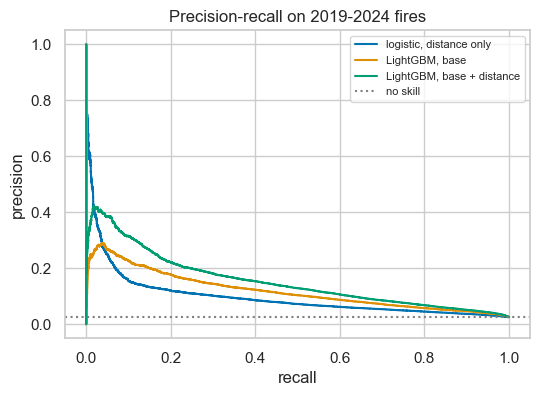

In [28]:
model_df = df.assign(CAUSE_CLASS=df['NWCG_CAUSE_CLASSIFICATION'].astype('category'),
                     OWNER=df['OWNER_DESCR'].astype('category'), STATE_C=df['STATE'].astype('category'),
                     LOG_DIST=np.log1p(df['DIST_KM']))
train, test = model_df[model_df['FIRE_YEAR'] < SPLIT_YEAR], model_df[model_df['FIRE_YEAR'] >= SPLIT_YEAR]
BASE = ['LATITUDE', 'LONGITUDE', 'DOY', 'CAUSE_CLASS', 'OWNER', 'STATE_C']

results, curves = [], {}
logit = LogisticRegression(class_weight='balanced', max_iter=1000).fit(train[['LOG_DIST']], train['LARGE'])
curves['logistic, distance only'] = logit.predict_proba(test[['LOG_DIST']])[:, 1]
for name, feats in [('LightGBM, base', BASE), ('LightGBM, base + distance', BASE + ['DIST_KM'])]:
    m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=63, verbose=-1, random_state=SEED)
    m.fit(train[feats], train['LARGE'])
    curves[name] = m.predict_proba(test[feats])[:, 1]

for name, p in curves.items():
    results.append({'model': name, 'ROC-AUC': roc_auc_score(test['LARGE'], p),
                    'PR-AUC': average_precision_score(test['LARGE'], p)})
results = pd.DataFrame(results).set_index('model')
results.loc['no-skill (prevalence)'] = [0.5, test['LARGE'].mean()]
display(results.style.format('{:.3f}'))

plt.figure(figsize=(6, 4))
for name, p in curves.items():
    prec, rec, _ = precision_recall_curve(test['LARGE'], p)
    plt.plot(rec, prec, label=name)
plt.axhline(test['LARGE'].mean(), color='gray', ls=':', label='no skill')
plt.xlabel('recall')
plt.ylabel('precision')
plt.title('Precision-recall on 2019-2024 fires')
plt.legend(fontsize=8)
savefig('pr_curves.png')
plt.show()

- **Distance alone** already ranks fires well above chance: ROC-AUC 0.756, PR-AUC 0.097, about 4 times the 0.025 no-skill level.
- **LightGBM with location, season, cause and owner** gets 0.813 / 0.119. **Adding distance** lifts it to **0.840 / 0.153, a 29 % relative gain in PR-AUC**, even though the base model already sees latitude and longitude. A tree model cannot rebuild "distance to the nearest of 52 k points" from raw coordinates, so the station join adds real information.
- The absolute PR-AUC is low because final size also depends on weather and fuel, which are not in the data. That is fine: the question is how much distance matters, not building a perfect size predictor.

#### Two more baselines: without cause, and with stations within 25 km

Cause is only known after an investigation, so a model used at discovery time cannot see it. We refit the baseline without it, and add the number of stations within 25 km.

In [29]:
NO_CAUSE = [f for f in BASE if f != 'CAUSE_CLASS']
more_variants = {'LightGBM, base without cause': NO_CAUSE,
                 'LightGBM, base without cause + distance': NO_CAUSE + ['DIST_KM'],
                 'LightGBM, base without cause + distance + stations 25 km': NO_CAUSE + ['DIST_KM', 'STATIONS_25KM'],
                 'LightGBM, base + distance + stations 25 km': BASE + ['DIST_KM', 'STATIONS_25KM']}
rows = []
for name, feats in more_variants.items():
    m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=63, verbose=-1, random_state=SEED)
    m.fit(train[feats], train['LARGE'])
    p = m.predict_proba(test[feats])[:, 1]
    rows.append({'model': name, 'ROC-AUC': roc_auc_score(test['LARGE'], p),
                 'PR-AUC': average_precision_score(test['LARGE'], p)})
display(pd.concat([results, pd.DataFrame(rows).set_index('model')]).style.format('{:.3f}'))

del model_df, train, test   # the full-size model tables are not needed below
_ = gc.collect()

,ROC-AUC,PR-AUC
model,,
"logistic, distance only",0.756,0.097
"LightGBM, base",0.813,0.119
"LightGBM, base + distance",0.840,0.153
no-skill (prevalence),0.500,0.025
"LightGBM, base without cause",0.817,0.129
"LightGBM, base without cause + distance",0.842,0.147
"LightGBM, base without cause + distance + stations 25 km",0.848,0.163
"LightGBM, base + distance + stations 25 km",0.845,0.160


- **Without cause**, the base model reaches 0.817 ROC-AUC / 0.129 PR-AUC, slightly *better* PR-AUC than with cause (0.119). Cause adds little once location, season and owner are known.
- **Distance still helps without cause:** 0.129 to 0.147 PR-AUC. Adding stations within 25 km lifts it again to **0.163, the best of all variants** (0.848 ROC-AUC), a 26 % relative gain over the no-cause base.
- So the station signal does not rely on cause, and a discovery-time model (no cause) is a realistic main model for Milestone 2. With cause and both station features the model gets 0.160.

### Question 1 as it will be built in Milestone 2

**How much does distance to the nearest fire station raise the chance that a fire becomes large, after accounting for where, when and why it started?**

- **Target:** `LARGE` = `FIRE_SIZE >= 100` acres (2.9 % of train fires, 2.5 % of test). 10 and 1,000 acres as sensitivity checks. Secondary target: contained after more than 1 day, on fires that have `CONT_DATE`.
- **Main predictor:** `DIST_KM`, plus `STATIONS_25KM` (section 7) and distance to the 2nd and 3rd nearest station.
- **Controls:** latitude, longitude, state, day of year (sin/cos), weekday, cause class, land owner, discovery hour (with a missing flag, since about 30 % of times are missing). Cause class is only known after an investigation, so it is a control in the explanatory model, and the predictive model is reported both with and without it.
- **Not used:** `FIRE_SIZE_CLASS` and containment fields (they are the outcome), `MTBS_ID` / ICS-209 join IDs (they exist only for big fires, so they leak the answer), `FIRE_NAME`, `SOURCE_SYSTEM_TYPE` (stands in for the year, see section 1).
- **Validation:** train 1992-2018, test 2019-2024; time-blocked folds inside the training years for tuning, plus a spatial check that holds out whole regions, since neighbouring fires are correlated. Fires on stacked office locations are dropped.
- **Imbalance:** class weights vs. random undersampling of small fires; threshold chosen on validation folds.
- **Models:** L2 logistic regression (which also gives the odds ratio), random forest, LightGBM (and XGBoost), each with and without the station features.
- **Metrics:** PR-AUC (main), ROC-AUC, F1 at the chosen threshold, confusion matrix, results per region. The adjusted odds ratio per doubling of distance answers the research question itself.
- **Interpretation:** SHAP values and partial dependence for `DIST_KM`, and a matched comparison of fires with the same cell, season and cause but different distances.

## 9. Question 2: what types of under-served areas exist?

A single fire is too noisy to describe an area, so we cluster **places**, not fires:

1. Split the lower 48 states into roughly 25 km x 25 km grid cells.
2. Keep cells with at least 30 fires over 33 years (enough to describe them) whose **median fire is 10 km or more from the nearest station**. These are the under-served cells.
3. Describe each cell by how its fires behave: fire rate, size, season, weekend share, distance, land owner mix.
4. **Cause is held out.** It is not a clustering feature; we use it afterwards to check whether the clusters mean something.

In [30]:
CELL_KM = 25
KM_PER_DEG = 111.32
MIN_FIRES = 30
UNDERSERVED_KM = 10
N_YEARS = df['FIRE_YEAR'].nunique()

c = df.loc[conus_f.index].copy()  # lower 48 inside the map extent, drops a few mis-located points
c['CY'] = (c['LATITUDE'] * KM_PER_DEG // CELL_KM).astype(int)
c['CX'] = (c['LONGITUDE'] * KM_PER_DEG * np.cos(np.radians(37.5)) // CELL_KM).astype(int)  # fixed-latitude scaling
angle = 2 * np.pi * c['DOY'] / 365.25
c['SEASON_SIN'], c['SEASON_COS'] = np.sin(angle), np.cos(angle)
c['SUMMER'] = c['DATE'].dt.month.between(6, 9)
c['WEEKEND'] = c['DATE'].dt.dayofweek >= 5
c['FEDERAL'] = c['OWNER_DESCR'].isin(FED_OWNERS)
c['PRIVATE'] = c['OWNER_DESCR'].isin(['PRIVATE', 'STATE OR PRIVATE'])
c['LIGHTNING'] = c['NWCG_CAUSE_CLASSIFICATION'].eq('Natural')

g = c.groupby(['CY', 'CX'])
cells = pd.DataFrame({
    'n_fires': g.size(),
    'lat': g['LATITUDE'].mean(), 'lon': g['LONGITUDE'].mean(),
    'log_fire_rate': np.log1p(g.size() / N_YEARS),
    'share_large': g['LARGE'].mean(),
    'median_log_size': g['LOG_SIZE'].median(),
    'p90_log_size': g['LOG_SIZE'].quantile(0.9),
    'summer_share': g['SUMMER'].mean(),
    'season_sin': g['SEASON_SIN'].mean(), 'season_cos': g['SEASON_COS'].mean(),
    'weekend_share': g['WEEKEND'].mean(),
    'log_median_dist': np.log(g['DIST_KM'].median()),
    'federal_share': g['FEDERAL'].mean(), 'private_share': g['PRIVATE'].mean(),
    'lightning_share': g['LIGHTNING'].mean(),  # held out, interpretation only
})
described = cells[cells['n_fires'] >= MIN_FIRES]
under = described[np.exp(described['log_median_dist']) >= UNDERSERVED_KM].copy()

in_under = c.set_index(['CY', 'CX']).index.isin(under.index)
print(f'{len(cells):,} occupied cells, {len(described):,} with {MIN_FIRES}+ fires, '
      f'{len(under):,} under-served (median distance >= {UNDERSERVED_KM} km)')
print(f"under-served cells hold {in_under.mean():.1%} of CONUS fires and "
      f"{c.loc[in_under, 'FIRE_SIZE'].sum() / c['FIRE_SIZE'].sum():.1%} of CONUS acres")

13,152 occupied cells, 9,087 with 30+ fires, 2,271 under-served (median distance >= 10 km)
under-served cells hold 11.5% of CONUS fires and 41.8% of CONUS acres


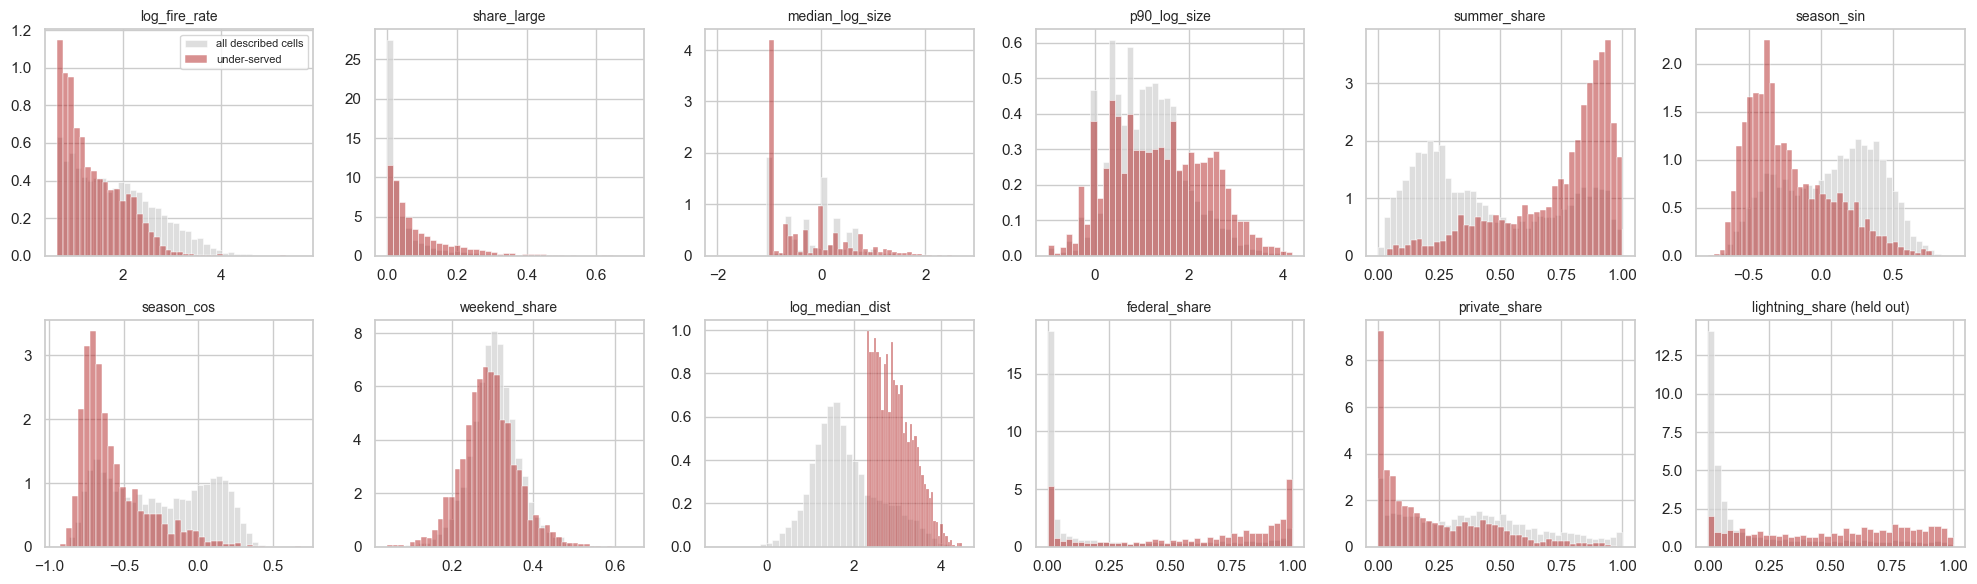

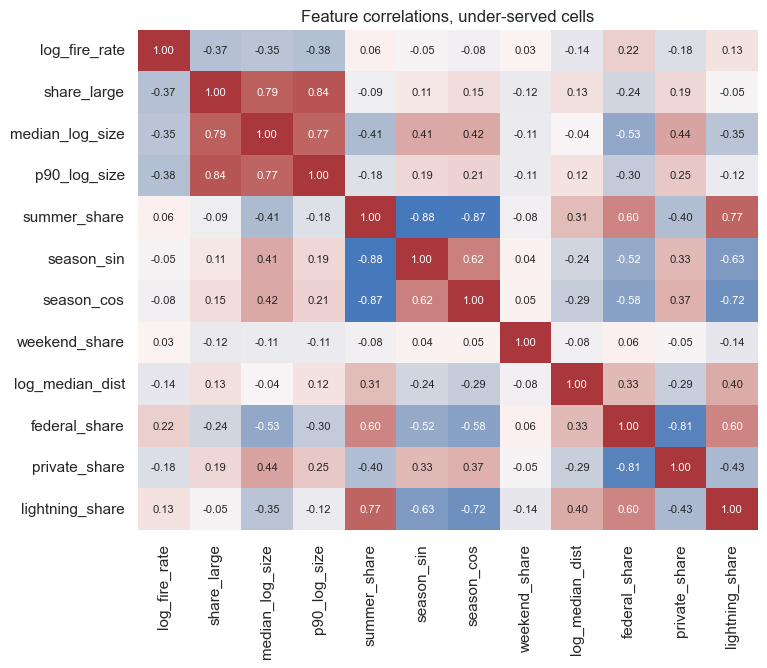

In [31]:
FEATURES = ['log_fire_rate', 'share_large', 'median_log_size', 'p90_log_size', 'summer_share', 'season_sin',
            'season_cos', 'weekend_share', 'log_median_dist', 'federal_share', 'private_share']

fig, axes = plt.subplots(2, 6, figsize=(20, 6))
for ax, feat in zip(axes.flat, FEATURES + ['lightning_share']):
    sns.histplot(described[feat], ax=ax, color='lightgray', stat='density', bins=40, label='all described cells')
    sns.histplot(under[feat], ax=ax, color='firebrick', stat='density', bins=40, alpha=0.5, label='under-served')
    ax.set_title(feat + (' (held out)' if feat == 'lightning_share' else ''), fontsize=10)
    ax.set_xlabel(''), ax.set_ylabel('')
axes.flat[0].legend(fontsize=8)
plt.tight_layout()
savefig('cell_features.png')
plt.show()

plt.figure(figsize=(8, 6.5))
sns.heatmap(under[FEATURES + ['lightning_share']].corr(), annot=True, fmt='.2f', cmap='vlag', center=0, cbar=False,
            annot_kws={'size': 8})
plt.title('Feature correlations, under-served cells')
savefig('cell_corr.png')
plt.show()

- **2,271 under-served cells** (median fire 10+ km from a station) hold only 11.5 % of lower-48 fires but **41.8 % of the acres burned**. Small in count, large in impact.
- Compared with all described cells they have a higher share of large fires, larger typical sizes, more federal land and more summer fires.
- **Correlations:** the three size features move together (0.77-0.84), and summer share is strongly tied to the season sin/cos pair (about -0.88). Federal and private share are near mirror images (-0.81). In Milestone 3 we will compare clustering on all features against a reduced set (one size feature, the sin/cos pair, federal share) and against PCA, so correlated features do not get double weight.
- **Held-out lightning share** is strongly related to summer share (0.77) and federal share (0.60). So if the clusters are real, they should separate lightning-dominated from human-dominated areas without ever seeing cause.

In [32]:
X = StandardScaler().fit_transform(under[FEATURES])


def hopkins(X, frac=0.1, seed=SEED):
    # ~0.5 = no more clustered than uniform noise, close to 1 = strong cluster structure
    rng = np.random.default_rng(seed)
    m = max(1, int(frac * len(X)))
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    uniform = rng.uniform(X.min(axis=0), X.max(axis=0), size=(m, X.shape[1]))
    u = nn.kneighbors(uniform, n_neighbors=1)[0][:, 0]
    w = nn.kneighbors(X[rng.choice(len(X), m, replace=False)], n_neighbors=2)[0][:, 1]
    return u.sum() / (u.sum() + w.sum())


scores = [hopkins(X, seed=SEED + i) for i in range(10)]
print(f'Hopkins statistic over 10 draws: mean {np.mean(scores):.3f}, min {np.min(scores):.3f}, max {np.max(scores):.3f}')

Hopkins statistic over 10 draws: mean 0.823, min 0.817, max 0.826


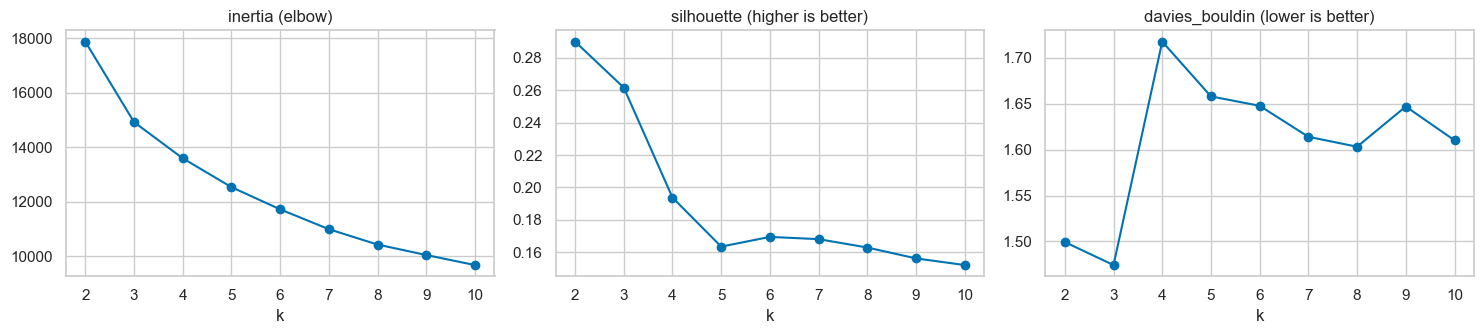

,inertia,silhouette,davies_bouldin
k,,,
2,17870.699,0.290,1.499
3,14916.646,0.262,1.474
4,13587.439,0.194,1.718
5,12529.469,0.164,1.658
6,11714.218,0.170,1.648
7,10985.397,0.168,1.614
8,10421.869,0.163,1.603
9,10037.357,0.156,1.647
10,9668.946,0.152,1.610


In [33]:
K_RANGE = range(2, 11)
sweep = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    sweep.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(X, km.labels_),
                  'davies_bouldin': davies_bouldin_score(X, km.labels_)})
sweep = pd.DataFrame(sweep).set_index('k')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col, note in zip(axes, sweep.columns, ['elbow', 'higher is better', 'lower is better']):
    sweep[col].plot(ax=ax, marker='o')
    ax.set_title(f'{col} ({note})')
plt.tight_layout()
savefig('cluster_selection.png')
plt.show()
display(sweep.round(3))

- **Hopkins statistic about 0.82** (stable across 10 draws), well above 0.5, so the under-served cells have real cluster structure and are not uniform noise.
- Silhouette is highest at k = 2 (0.29), Davies-Bouldin is lowest at k = 3 (1.47), and the elbow has no sharp bend. k = 2 only splits "western federal summer" from "everything else", which is too coarse to act on, so we use **k = 4 as a preliminary choice** for interpretation.
- A silhouette around 0.19 at k = 4 means the groups overlap. Milestone 3 will compare K-Means with a Gaussian mixture (soft membership suits overlapping groups) and HDBSCAN, and check stability with bootstrap resampling (adjusted Rand index between runs).

cluster,0,1,2,3
cells,393.00,534.00,968.00,376.00
fires_per_cell,59.22,104.05,183.71,117.09
log_fire_rate,0.98,1.28,1.64,1.30
share_large,0.24,0.05,0.04,0.14
median_log_size,0.57,-0.43,-0.89,0.52
p90_log_size,2.75,1.18,0.69,1.95
summer_share,0.85,0.70,0.87,0.34
season_sin,-0.34,-0.16,-0.38,0.24
season_cos,-0.68,-0.56,-0.69,-0.19
weekend_share,0.27,0.30,0.30,0.29


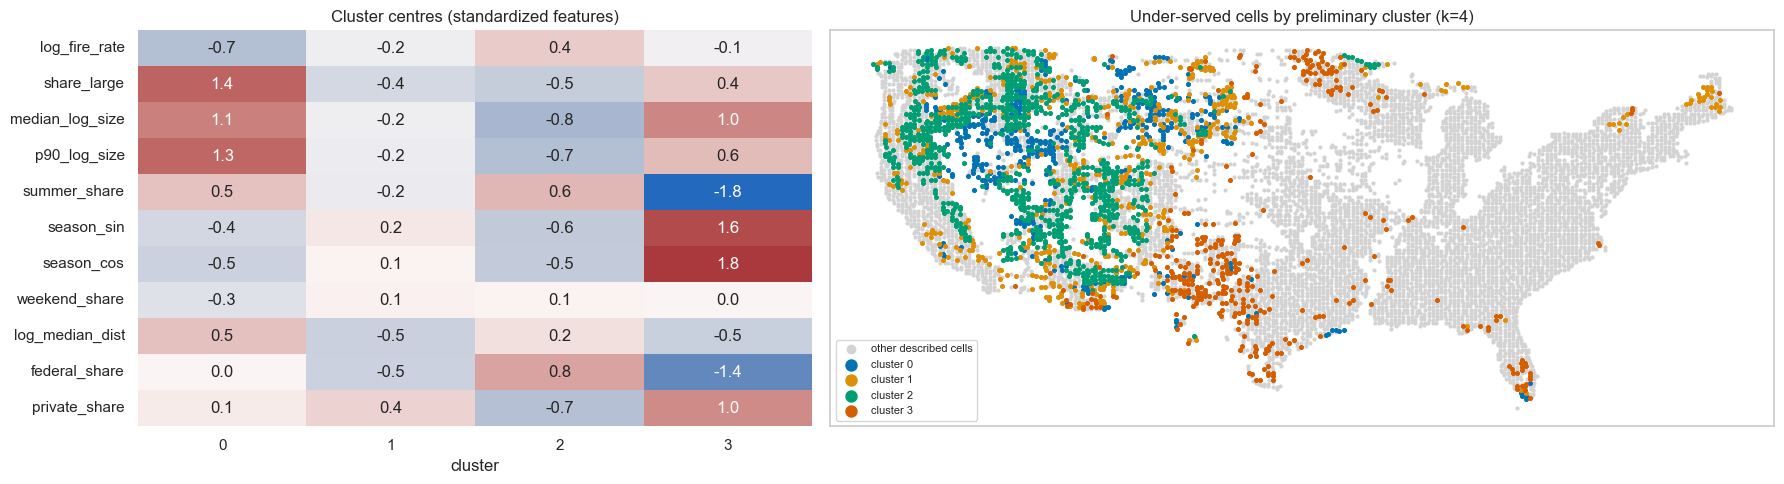

In [34]:
K_PRELIM = 4
km = KMeans(n_clusters=K_PRELIM, n_init=10, random_state=SEED).fit(X)
under['cluster'] = km.labels_

profile = under.groupby('cluster').agg(cells=('n_fires', 'size'), fires_per_cell=('n_fires', 'mean'),
                                       **{f: (f, 'mean') for f in FEATURES + ['lightning_share']})
profile['median_dist_km'] = np.exp(profile['log_median_dist'])
display(profile.drop(columns=['log_median_dist']).round(2).T)

fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [1, 1.4]})
z = pd.DataFrame(km.cluster_centers_, columns=FEATURES)
sns.heatmap(z.T, annot=True, fmt='.1f', cmap='vlag', center=0, ax=axes[0], cbar=False)
axes[0].set_title('Cluster centres (standardized features)')
axes[0].set_xlabel('cluster')
axes[1].scatter(described['lon'], described['lat'], s=4, color='lightgray', label='other described cells')
for k_, s in under.groupby('cluster'):
    axes[1].scatter(s['lon'], s['lat'], s=7, label=f'cluster {k_}')
axes[1].set_title(f'Under-served cells by preliminary cluster (k={K_PRELIM})')
axes[1].set_xticks([]), axes[1].set_yticks([])
axes[1].legend(markerscale=3, fontsize=8, loc='lower left')
plt.tight_layout()
savefig('cluster_profile_map.png')
plt.show()

Four preliminary types of under-served area (cause was **not** used to build them; the lightning share is the held-out check):

| Cluster | Cells | What the fires look like | Held-out lightning share | Where |
|---|---|---|---|---|
| **0: Remote large-fire wildlands** | 393 | fewest fires, but 24 % become large; summer; farthest from stations (median 24 km) | 62 % | Great Basin, Montana, Wyoming |
| **1: Mixed rural fringe** | 534 | average on most features, slightly more private land | 36 % | edges of the West, upper Midwest, northern New England |
| **2: Busy federal forests** | 968 | most fires per cell, but tiny (median about 0.1 acre); summer; 88 % federal | 70 % | Rockies, Sierra Nevada, Arizona / New Mexico forests |
| **3: Spring private-land fires** | 376 | only 34 % in summer (spring peak), 45 % private land, 14 % large | 15 % | Oklahoma / Texas, Florida, northern Minnesota |

- The held-out lightning share differs strongly (15 % to 70 %), so the clusters capture real differences in fire regime, not just noise.
- **Cluster 2 is the clearest sign of the data gap:** far from structural stations, yet its fires stay tiny. These are national forests with their own wildland crews, so they are less under-served than the distance suggests.
- **Each type points to a different kind of help:** aviation, detection and pre-positioned crews for cluster 0; new or volunteer stations and burn rules for cluster 3; probably no change for cluster 2.

### Are the clusters real? Stability, feature-group and held-out checks

Three checks on the preliminary k = 4 clustering:

1. **Bootstrap stability:** refit on resampled cells, label every cell with the refit model and compare with the main labels (adjusted Rand index, 1 = identical).
2. **Which features drive the clusters:** drop one group of features, refit, and compare. A low ARI means that group shapes the clusters.
3. **A different algorithm and held-out variables:** a Gaussian mixture (soft clusters, suited to overlapping groups) for comparison, and the land-owner and region mix of each cluster, which were not inputs (federal and private *shares* are inputs, but the full owner breakdown and region are not).

bootstrap ARI over 30 refits: 0.88 +/- 0.15


,ARI vs all features
"season (summer share, sin/cos)",0.34
"size outcome (share large, median and p90 size)",0.35
"land owner (federal, private share)",0.42
distance,0.85
fire rate,0.89
weekend share,0.96


K-Means vs Gaussian mixture at k=4: ARI 0.45; GMM BIC is lowest at k=6


,2,3,4,5,6,7,8,9,10
GMM BIC,44138.0,34935.0,33910.0,33289.0,31317.0,33069.0,31420.0,31616.0,31502.0


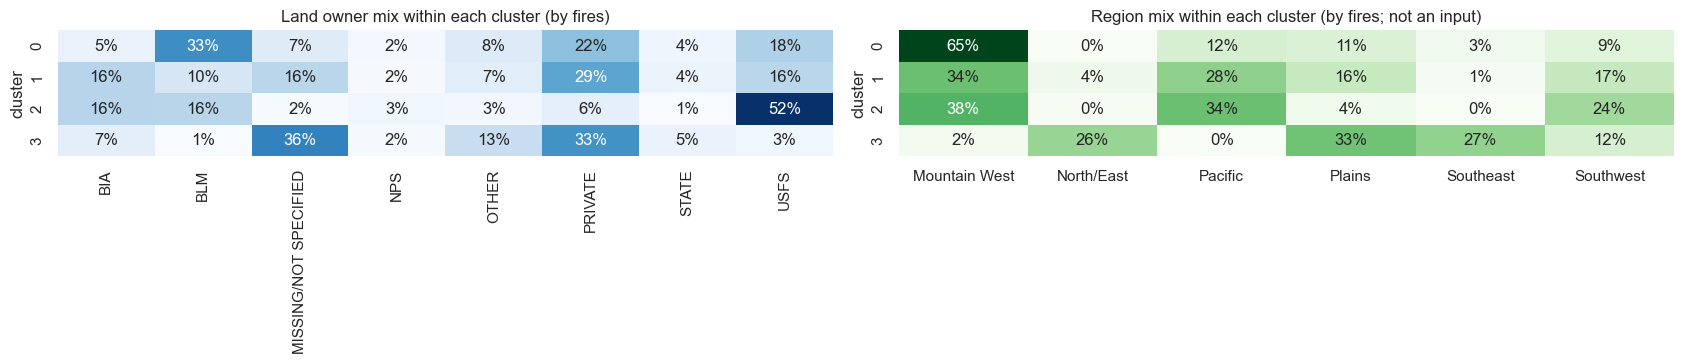

In [35]:
labels = under['cluster'].to_numpy()
rng = np.random.default_rng(SEED)
boot_ari = []
for b in range(30):
    idx = rng.choice(len(X), len(X), replace=True)
    kb = KMeans(n_clusters=K_PRELIM, n_init=10, random_state=b).fit(X[idx])
    boot_ari.append(adjusted_rand_score(labels, kb.predict(X)))
print(f'bootstrap ARI over 30 refits: {np.mean(boot_ari):.2f} +/- {np.std(boot_ari):.2f}')

FEATURE_GROUPS = {'size outcome (share large, median and p90 size)': ['share_large', 'median_log_size', 'p90_log_size'],
                  'distance': ['log_median_dist'],
                  'season (summer share, sin/cos)': ['summer_share', 'season_sin', 'season_cos'],
                  'land owner (federal, private share)': ['federal_share', 'private_share'],
                  'fire rate': ['log_fire_rate'],
                  'weekend share': ['weekend_share']}
ablation = {}
for name, drop in FEATURE_GROUPS.items():
    keep = [i for i, f in enumerate(FEATURES) if f not in drop]
    ablation[name] = adjusted_rand_score(
        labels, KMeans(n_clusters=K_PRELIM, n_init=10, random_state=SEED).fit_predict(X[:, keep]))
display(pd.Series(ablation, name='ARI vs all features').sort_values().round(2).to_frame())

gmm_bic = pd.Series({k: GaussianMixture(k, covariance_type='full', n_init=2, random_state=SEED).fit(X).bic(X)
                     for k in K_RANGE}, name='GMM BIC')
gmm = GaussianMixture(K_PRELIM, covariance_type='full', n_init=5, random_state=SEED).fit(X)
print(f'K-Means vs Gaussian mixture at k={K_PRELIM}: ARI {adjusted_rand_score(labels, gmm.predict(X)):.2f}; '
      f'GMM BIC is lowest at k={gmm_bic.idxmin()}')
display(gmm_bic.round(0).to_frame().T)

# held-out mix, weighted by fires
fires_u = c.loc[in_under, ['CY', 'CX', 'STATE', 'OWNER_DESCR']].copy()
fires_u['cluster'] = under['cluster'].reindex(pd.MultiIndex.from_frame(fires_u[['CY', 'CX']])).to_numpy()
top_owners_u = fires_u['OWNER_DESCR'].value_counts().index[:7]
fires_u['owner'] = fires_u['OWNER_DESCR'].where(fires_u['OWNER_DESCR'].isin(top_owners_u), 'OTHER')
fires_u['region'] = fires_u['STATE'].map(REGION6).fillna('North/East')
fig, axes = plt.subplots(1, 2, figsize=(17, 3.8))
sns.heatmap(pd.crosstab(fires_u['cluster'], fires_u['owner'], normalize='index'), annot=True, fmt='.0%',
            cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title('Land owner mix within each cluster (by fires)')
sns.heatmap(pd.crosstab(fires_u['cluster'], fires_u['region'], normalize='index'), annot=True, fmt='.0%',
            cmap='Greens', cbar=False, ax=axes[1])
axes[1].set_title('Region mix within each cluster (by fires; not an input)')
for ax in axes:
    ax.set_xlabel('')
plt.tight_layout()
savefig('cluster_heldout.png')
plt.show()

- **Fairly stable, not perfectly:** bootstrap ARI 0.88 with a spread of 0.15, so most refits reproduce the same four groups, but some draws split them differently. That fits the low silhouette (0.19).
- **What drives the clusters:** dropping season (ARI 0.34), the size-outcome features (0.35) or land owner (0.42) changes the clusters a lot; dropping distance (0.85), fire rate (0.89) or weekend share (0.96) changes them little. Distance matters less here because every cell is already under-served (10+ km), so the cells differ more in *what kind* of fire they have than in how far help is.
- **Circularity to watch:** the clusters rest partly on fire size, which is the supervised target in question 1. Calling a cluster "needs help" partly because its fires are big is circular. In Milestone 3 we will rerun without the size features and see which types survive.
- **Gaussian mixture:** agreement with K-Means is only moderate (ARI 0.45), and its BIC prefers k = 6. Milestone 3 will compare k = 4 against 5-6 groups before fixing the typology.
- **Held-out mix matches the names:** cluster 0 (remote large-fire wildlands) is 65 % Mountain West and 33 % BLM land; cluster 2 (busy federal forests) is 52 % Forest Service; cluster 3 (spring private-land fires) has almost no western fires and is spread over the Plains (33 %), Southeast (27 %) and North/East (26 %), on private or unlisted land (69 %). Region was never an input, so this is a real check.

### From clusters to "what help does each type need?"

To make the step from a cluster profile to a recommendation explicit, each type of help gets a transparent scoring rule: a weighted sum of the cluster's standardized centre (positive weight = more of this feature means more need), divided by the total weight. A cluster gets a suggestion when its score is at least 0.5 standard deviations above average. The rules are a starting point to argue about, not a result.

In [36]:
HELP_RULES = {
    'Remote detection and fast initial attack': {'log_median_dist': 1, 'share_large': 1, 'p90_log_size': 1},
    'Extended-attack and surge capacity': {'p90_log_size': 1, 'median_log_size': 1, 'summer_share': 0.5},
    'New or volunteer station': {'private_share': 1, 'federal_share': -1, 'share_large': 0.5, 'log_median_dist': 0.5},
    'Prevention and outreach': {'log_fire_rate': 1, 'private_share': 1, 'weekend_share': 0.5, 'summer_share': -0.5},
}
HELP_THRESHOLD = 0.5

help_scores = pd.DataFrame({name: sum(w * z[f] for f, w in rule.items()) / sum(abs(w) for w in rule.values())
                            for name, rule in HELP_RULES.items()})
suggested = help_scores.apply(lambda r: ' + '.join(r[r >= HELP_THRESHOLD].sort_values(ascending=False).index)
                              or 'maintain current coverage', axis=1)
display(help_scores.round(2).assign(suggested=suggested))

,Remote detection and fast initial attack,Extended-attack and surge capacity,New or volunteer station,Prevention and outreach,suggested
0,1.08,1.08,0.36,-0.31,Extended-attack and surge capacity + Remote de...
1,-0.35,-0.18,0.13,0.12,maintain current coverage
2,-0.31,-0.45,-0.52,-0.17,maintain current coverage
3,0.17,0.29,0.78,0.58,New or volunteer station + Prevention and outr...


- **Cluster 0, remote large-fire wildlands:** remote detection and fast initial attack (1.08) plus extended-attack and surge capacity (1.08).
- **Cluster 3, spring private-land fires:** a new or volunteer station (0.78) plus prevention and outreach (0.58).
- **Clusters 1 and 2:** no score passes 0.5, so "maintain current coverage". For cluster 2 (busy federal forests) that fits: fires stay tiny because wildland crews already cover it.
- These rules reproduce the recommendations we wrote by hand above, which is reassuring but not independent, since we wrote both. The rules also use the size features, so they share the circularity noted above.

### Would more stations close the gaps?

The obvious fix for an under-served area is a new station. We test that with a greedy **maximal covering** placement: candidate sites are the locations of large fires that were not covered (10 km) in 1992-2018, and each step adds the site that covers the most still-uncovered large fires. We then measure coverage of the **2019-2024** large fires, which the placement never saw.

,large 2019-24 fires covered,their acres covered
new stations,,
0,57.4%,31.3%
10,58.0%,31.6%
25,58.3%,31.8%
50,58.9%,32.3%
100,59.8%,33.7%
200,61.3%,37.9%


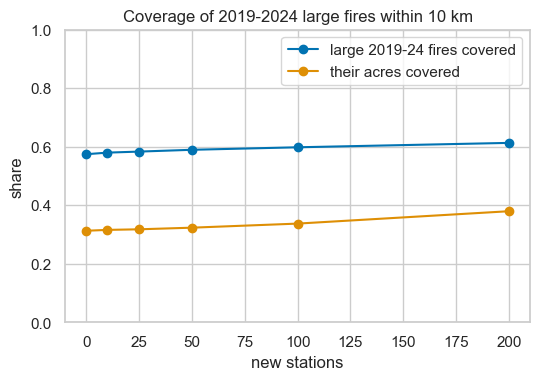

first 100 sites by preliminary cluster of their cell (NaN = not an under-served cell): {0.0: 32, 3.0: 25, nan: 25, 2.0: 16, 1.0: 2}


In [37]:
radius = COVER_KM / EARTH_KM
past = df[(df['FIRE_YEAR'] < SPLIT_YEAR) & df['LARGE'] & (df['DIST_KM'] >= COVER_KM)]
past_xy = np.radians(past[['LATITUDE', 'LONGITUDE']].to_numpy())
cand = past.sample(min(20_000, len(past)), random_state=SEED)
cand_xy = np.radians(cand[['LATITUDE', 'LONGITUDE']].to_numpy())
covers = BallTree(past_xy, metric='haversine').query_radius(cand_xy, r=radius)

covered = np.zeros(len(past), dtype=bool)
chosen = []
for _ in range(200):
    gains = np.fromiter(((~covered[i]).sum() for i in covers), dtype=int, count=len(covers))
    best = int(gains.argmax())
    chosen.append(best)
    covered[covers[best]] = True

future = df[(df['FIRE_YEAR'] >= SPLIT_YEAR) & df['LARGE']]
future_xy = np.radians(future[['LATITUDE', 'LONGITUDE']].to_numpy())
st_xy = np.radians(st[['lat', 'lon']].to_numpy())
budget_rows = []
for b in [0, 10, 25, 50, 100, 200]:
    sites = np.vstack([st_xy, cand_xy[chosen[:b]]])
    d = BallTree(sites, metric='haversine').query(future_xy, k=1)[0][:, 0] * EARTH_KM
    within = d < COVER_KM
    budget_rows.append({'new stations': b, 'large 2019-24 fires covered': within.mean(),
                        'their acres covered': future['FIRE_SIZE'].to_numpy()[within].sum() / future['FIRE_SIZE'].sum()})
budget = pd.DataFrame(budget_rows).set_index('new stations')
display(budget.style.format('{:.1%}'))

ax = budget.plot(marker='o', figsize=(6, 3.8))
ax.set_ylim(0, 1)
ax.set_title(f'Coverage of 2019-2024 large fires within {COVER_KM} km')
ax.set_ylabel('share')
savefig('coverage_budget.png')
plt.show()

site_lat, site_lon = np.degrees(cand_xy[chosen[:100]]).T
site_cells = pd.MultiIndex.from_arrays([(site_lat * KM_PER_DEG // CELL_KM).astype(int),
                                        (site_lon * KM_PER_DEG * np.cos(np.radians(37.5)) // CELL_KM).astype(int)])
print('first 100 sites by preliminary cluster of their cell (NaN = not an under-served cell):',
      under['cluster'].reindex(site_cells).value_counts(dropna=False).to_dict())

- **Adding stations helps, but slowly.** 200 greedily placed new stations raise coverage of 2019-2024 large fires from 57.4 % to 61.3 %, and their acres from 31.3 % to 37.9 %. Large fires are spread over huge areas, so each new 10 km circle catches only a few.
- The first 100 sites fall mostly in **cluster 0 (32)** and **cluster 3 (25)**, then cluster 2 (16) and cluster 1 (2); 25 fall outside the under-served cells.
- So **more stations alone will not close the gaps**. The useful output of question 2 is the typology itself: it says which areas a station would help (spring private-land fires near towns) and which need a different approach (remote wildlands).

## 10. Summary and plan

**Why the second dataset is needed:** FPA-FOD says where fires started but not where help comes from. The HIFLD station layer (52 k stations, `fire_station_data/`) supplies that and is clean, with three caveats: it is a present-day snapshot, it is mostly structural (municipal/county) stations, and coverage of federal wildland crews is thin.

**Question 1 (supervised, Milestone 2):** *How much does distance to the nearest fire station raise the chance that a fire becomes large, after accounting for where, when and why it started?*
- Viable: the share of large fires rises about 22x from the nearest to the farthest distance band, the trend holds within every region x cause group and in recent years, and adding distance lifts an untuned LightGBM from 0.119 to 0.153 PR-AUC on 2019-2024 fires.

**Question 2 (unsupervised, Milestone 3):** *Among areas that have fires but no station nearby, what distinct types exist, and what kind of help would each type need?*
- Viable: 2,271 under-served cells hold 42 % of burned acres; Hopkins 0.82; a preliminary k = 4 gives four interpretable types that separate cleanly on held-out cause, and a coverage experiment shows why one fix (more stations) does not fit all of them.

**Limitations we will carry forward:**
1. Distance is associated with larger fires; it is not proven to cause them (fuel, terrain, weather and detection delay are not in the data).
2. Wildland stations are under-represented, which overstates distance on federal land.
3. Station locations are a current snapshot applied to fires back to 1992.
4. Straight-line distance, not road travel time.
5. Data-quality issues from section 1 still apply (rounded sizes and times, office-location coordinate clusters, missing containment dates).

### Added checks (from the comparison with a teammate's EDA)

**Question 1:** adjusted odds ratio **1.80 per doubling of distance** [1.76, 1.84], 89 % of the raw effect; above 1 in all 17 region / owner / cause groups and all 33 years; larger for stricter cutoffs (1.55 / 1.80 / 2.07 for 10 / 100 / 1,000 acres); weakened but never removed when up to 75 % of stations are deleted. Tiny fires are not missing far from stations, so under-reporting does not explain it. A discovery-time model without cause still gains from distance (0.129 to 0.147 PR-AUC, 0.163 with stations within 25 km).

**Question 2:** bootstrap ARI 0.88; clusters are driven by season, fire size and land owner more than distance; a Gaussian mixture agrees only moderately (ARI 0.45) and prefers k = 6; held-out region and owner mix match the cluster names; transparent help rules reproduce the hand-written recommendations.

**New items for later milestones:** spatial validation (hold out regions); report the predictive model with and without cause; rerun the clustering without the size features to remove the circularity with question 1; compare k = 4 with k = 5-6; try other grid sizes.